# Exercice MLP : prédire les locations de vélos (Bike Sharing)

## 1. Introduction

Je prédis `cnt`, le nombre de vélos loués, à partir du calendrier et de la météo. C'est une **régression** : la cible est un nombre.

- **Modèle** : uniquement des perceptrons multi-couches (MLP) avec Keras, activation ReLU (`max(0, x)`).
- **Métrique** : la MAE (*Mean Absolute Error*), moyenne des écarts `|réel − prédit|`, en nombre de vélos.
- **Données** : Bike Sharing (UCI), en version journalière (`day.csv`) et horaire (`hour.csv`), sur 2011 et 2012.

**Question du projet** : que gagne le modèle quand on passe au niveau horaire et qu'on lui donne l'heure ?

| Acte | Jeu | Contenu |
| --- | --- | --- |
| 1 | `day.csv` | Une référence naïve et trois MLP : le sur-apprentissage sur un petit jeu |
| 2 | `hour.csv` | Le protocole complet : entrées, profondeur, largeur, perte, régularisation, Keras Tuner |
| 3 | les deux | Les deux modèles retenus, comparés sur le total journalier des mêmes jours de test |

**Reproductibilité** : graine 42 et calculs déterministes. Les chiffres commentés sont ceux de l'exécution enregistrée ; sur une autre machine, les décimales peuvent légèrement changer.

In [1]:
# Configuration : imports, graine, versions
import os, sys, time, shutil, subprocess, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
import tensorflow as tf
import keras
from keras import layers, regularizers
import logging
tf.get_logger().setLevel(logging.ERROR)   # masque les avertissements TensorFlow (GPU absent, fonctions dépréciées)
logging.getLogger("absl").setLevel(logging.ERROR)
import matplotlib

try:
    import keras_tuner as kt
except ImportError:  # Keras Tuner n'est pas préinstallé sur Colab
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "keras-tuner"])
    import keras_tuner as kt

SEED = 42
keras.utils.set_random_seed(SEED)               # graine de Python, NumPy et TensorFlow
tf.config.experimental.enable_op_determinism()  # mêmes calculs => mêmes résultats
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Python      ", sys.version.split()[0])
print("NumPy       ", np.__version__)
print("matplotlib  ", matplotlib.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("TensorFlow  ", tf.__version__)
print("Keras       ", keras.__version__)
print("Keras Tuner ", kt.__version__)

Python       3.13.17
NumPy        2.5.5
matplotlib   3.11.2
pandas       3.1.1
scikit-learn 1.9.1
TensorFlow   2.21.0
Keras        3.15.1
Keras Tuner  1.4.8


## 2. Chargement et description des deux jeux

Je charge les deux fichiers et je regarde leurs dimensions, leurs types et les valeurs manquantes.

In [2]:
# Chargement : fichiers locaux, sinon téléchargement depuis l'UCI (utile sur Colab)
URL_UCI = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
if not (os.path.exists("day.csv") and os.path.exists("hour.csv")):
    import urllib.request, zipfile, io
    with urllib.request.urlopen(URL_UCI) as r:
        archive = zipfile.ZipFile(io.BytesIO(r.read()))
    for f in ["day.csv", "hour.csv"]:
        archive.extract(f)

day = pd.read_csv("day.csv", parse_dates=["dteday"])
hour = pd.read_csv("hour.csv", parse_dates=["dteday"])

for nom, df in [("day.csv", day), ("hour.csv", hour)]:
    print(f"{nom} : {df.shape[0]} lignes, {df.shape[1]} colonnes, "
          f"du {df.dteday.min().date()} au {df.dteday.max().date()}, "
          f"valeurs manquantes : {int(df.isna().sum().sum())}")

day.csv : 731 lignes, 16 colonnes, du 2011-01-01 au 2012-12-31, valeurs manquantes : 0
hour.csv : 17379 lignes, 17 colonnes, du 2011-01-01 au 2012-12-31, valeurs manquantes : 0


In [3]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print(hour.dtypes.to_string())

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64


In [5]:
hour.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


**Ce que je retiens.** `day.csv` a 731 lignes, `hour.csv` 17 379 (avec l'heure `hr` en plus), sans valeur manquante. La cible horaire va de 1 à 977 (moyenne 189, médiane 142). `weathersit = 4` (fortes pluies, neige) n'apparaît que 3 fois : le modèle ne pourra rien en apprendre de fiable.

In [6]:
# Heures absentes de hour.csv : un jour complet devrait avoir 24 lignes
n_heures = hour.groupby("dteday").size()
print("Jours avec moins de 24 heures :", int((n_heures < 24).sum()), "sur", len(n_heures))
print("Lignes attendues :", len(day) * 24, "| lignes présentes :", len(hour),
      "| manquantes :", len(day) * 24 - len(hour))
print("\nJours avec moins de 20 heures :")
print(n_heures[n_heures < 20].to_string())

Jours avec moins de 24 heures : 76 sur 731
Lignes attendues : 17544 | lignes présentes : 17379 | manquantes : 165

Jours avec moins de 20 heures :
dteday
2011-01-18    12
2011-01-26    16
2011-01-27     8
2011-02-22    18
2011-08-27    18
2011-08-28    17
2012-10-29     1
2012-10-30    11


**Heures manquantes.** Il manque 165 heures (17 379 lignes au lieu de 17 544) : les heures sans location semblent absentes du fichier, surtout la nuit. Le 29 octobre 2012 n'a qu'une heure enregistrée et le 30 octobre 11, probablement à cause de l'ouragan Sandy. Ces deux jours sont dans le test (voir l'acte 3).

## 3. Exploration et identification des variables à risque de fuite

Je regarde la distribution de la cible, puis comment les locations varient selon l'heure, le jour et la saison.

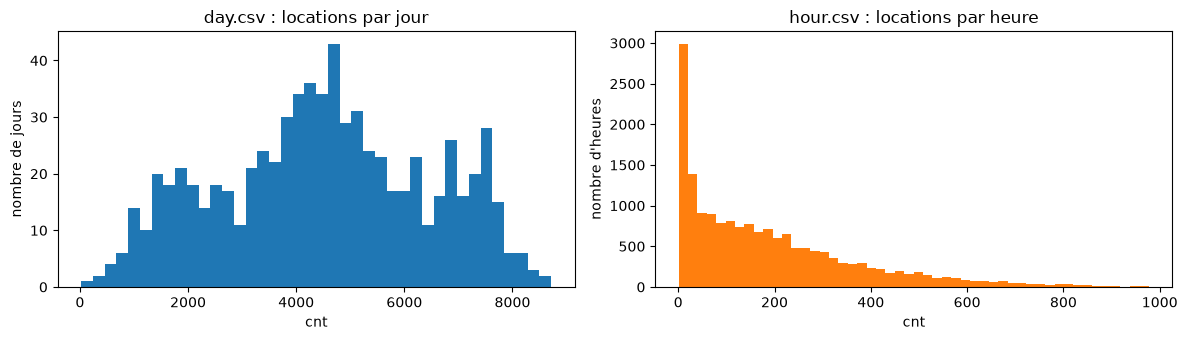

Asymétrie (skewness) de cnt : journalier -0.05 | horaire 1.28


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(day.cnt, bins=40, color="tab:blue")
ax[0].set(title="day.csv : locations par jour", xlabel="cnt", ylabel="nombre de jours")
ax[1].hist(hour.cnt, bins=50, color="tab:orange")
ax[1].set(title="hour.csv : locations par heure", xlabel="cnt", ylabel="nombre d'heures")
plt.tight_layout(); plt.show()
print("Asymétrie (skewness) de cnt : journalier", round(day.cnt.skew(), 2),
      "| horaire", round(hour.cnt.skew(), 2))

**Distribution de la cible.** Le nombre horaire est très asymétrique (1,28) : beaucoup d'heures creuses et une longue queue d'heures de pointe. Une perte MSE, qui élève les erreurs au carré, va surtout viser ces pointes : d'où l'intérêt de tester aussi la MAE et Huber à l'étape 4.

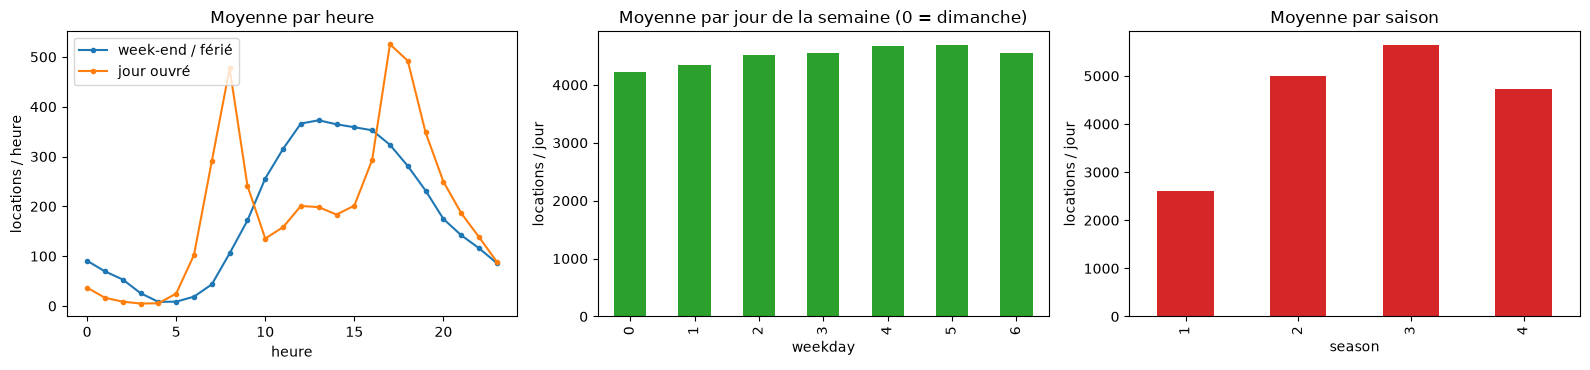

Mois couverts par chaque valeur de season :
mnth    1   2   3   4   5   6   7   8   9   10  11  12
season                                                
1       62  57  40   0   0   0   0   0   0   0   0  22
2        0   0  22  60  62  40   0   0   0   0   0   0
3        0   0   0   0   0  20  62  62  44   0   0   0
4        0   0   0   0   0   0   0   0  16  62  60  40


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
prof = hour.groupby(["hr", "workingday"]).cnt.mean().unstack()
prof.columns = ["week-end / férié", "jour ouvré"]
prof.plot(ax=ax[0], marker=".")
ax[0].set(title="Moyenne par heure", xlabel="heure", ylabel="locations / heure")
day.groupby("weekday").cnt.mean().plot.bar(ax=ax[1], color="tab:green")
ax[1].set(title="Moyenne par jour de la semaine (0 = dimanche)", xlabel="weekday", ylabel="locations / jour")
day.groupby("season").cnt.mean().plot.bar(ax=ax[2], color="tab:red")
ax[2].set(title="Moyenne par saison", xlabel="season", ylabel="locations / jour")
plt.tight_layout(); plt.show()
print("Mois couverts par chaque valeur de season :")
print(pd.crosstab(day.season, day.mnth))

**Profils.** Les jours ouvrés ont deux pics (8 h et 17-18 h), le week-end une seule bosse l'après-midi : l'effet de l'heure dépend du type de jour, une interaction non linéaire qu'un MLP peut apprendre. Les jours de la semaine sont proches. La saison 1 couvre fin décembre à mars : c'est l'hiver, même si l'UCI l'appelle « printemps ».

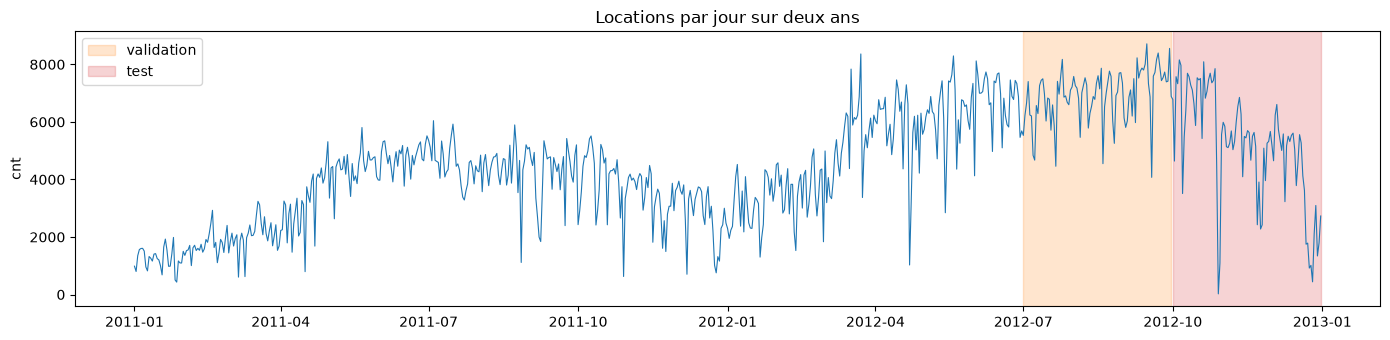

Moyenne journalière 2011 : 3406 | 2012 : 5600


In [9]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(day.dteday, day.cnt, lw=0.8)
ax.axvspan(pd.Timestamp("2012-07-01"), pd.Timestamp("2012-09-30"), color="tab:orange", alpha=0.2, label="validation")
ax.axvspan(pd.Timestamp("2012-10-01"), pd.Timestamp("2012-12-31"), color="tab:red", alpha=0.2, label="test")
ax.set(title="Locations par jour sur deux ans", ylabel="cnt"); ax.legend()
plt.tight_layout(); plt.show()
print("Moyenne journalière 2011 :", round(day[day.yr == 0].cnt.mean()),
      "| 2012 :", round(day[day.yr == 1].cnt.mean()))

**Tendance.** La moyenne passe de 3 406 locations par jour en 2011 à 5 600 en 2012, soit +64 %. Le service grandit. La validation (été 2012, zone orange) est la période la plus chargée des deux ans. Le test (automne 2012, zone rouge) redescend avec le froid. La variable `yr` sera la seule à porter cette croissance.

In [10]:
num = ["temp", "atemp", "hum", "windspeed", "instant", "casual", "registered", "cnt"]
print("Corrélation avec cnt (hour.csv) :")
print(hour[num].corr()["cnt"].round(3).to_string())
print("\nCorrélation temp / atemp :", round(hour.temp.corr(hour.atemp), 3))

Corrélation avec cnt (hour.csv) :
temp          0.405
atemp         0.401
hum          -0.323
windspeed     0.093
instant       0.278
casual        0.695
registered    0.972
cnt           1.000

Corrélation temp / atemp : 0.988


**Corrélations avec `cnt`.** Température 0,40, humidité −0,32, vent 0,09. `temp` et `atemp` sont presque identiques (0,988), mais la redondance ne gêne pas un MLP. `registered` (0,97) et `casual` (0,70) sont très liés à la cible : c'est le signe d'une fuite.

### Variables à risque de fuite

Une fuite de données est une entrée qui contient déjà la réponse. D'après l'UCI, `casual` (usagers occasionnels) et `registered` (abonnés) ont pour somme `cnt`. Je le vérifie.

In [11]:
# Vérification de la fuite : casual + registered = cnt ?
for nom, df in [("day.csv", day), ("hour.csv", hour)]:
    egal = (df.casual + df.registered == df.cnt)
    print(f"{nom} : casual + registered == cnt sur {egal.sum()} lignes / {len(df)}")
# Et la version journalière est bien la somme des heures
somme = hour.groupby("dteday").cnt.sum()
print("Somme horaire == cnt journalier pour chaque jour :", bool((somme.values == day.set_index("dteday").cnt.values).all()))

day.csv : casual + registered == cnt sur 731 lignes / 731
hour.csv : casual + registered == cnt sur 17379 lignes / 17379
Somme horaire == cnt journalier pour chaque jour : True


**Résultat.** `casual + registered = cnt` sur 100 % des lignes : ces deux variables sont des morceaux de la cible, inconnus au moment de prévoir. **Je les retire**, ainsi que `instant` (un numéro de ligne ; la tendance est déjà portée par `yr`) et `dteday` (la date brute, déjà résumée par `yr`, `mnth`, `weekday` et `holiday`). Le total de `day.csv` est bien la somme des heures de `hour.csv`, ce qui rend possible l'acte 3.

## 4. Pré-traitement et découpage

### 4.1 Découpage chronologique, identique pour les deux jeux

| Jeu | Période | Rôle |
| --- | --- | --- |
| Entraînement | janvier 2011 → juin 2012 | ajuster les poids |
| Validation | juillet → septembre 2012 | comparer les essais et choisir |
| Test | octobre → décembre 2012 | mesurer une seule fois les modèles finaux |

Je découpe dans l'ordre du temps plutôt qu'au hasard :

1. **C'est l'usage réel** : on prévoit le futur à partir du passé.
2. **Pas de fuite temporelle** : au hasard, deux heures voisines, presque identiques, iraient l'une à l'entraînement et l'autre au test, et la MAE serait trop optimiste.
3. **Une vraie généralisation** : le test porte sur une période jamais vue.

Limite : le test ne couvre que l'automne 2012 ; la partie 10 chiffre l'écart avec un découpage aléatoire. Tous les choix se font sur la validation.

In [12]:
FIN_TRAIN, FIN_VAL = pd.Timestamp("2012-06-30"), pd.Timestamp("2012-09-30")

def periode(dates):
    return np.where(dates <= FIN_TRAIN, "train", np.where(dates <= FIN_VAL, "val", "test"))

day["jeu"] = periode(day.dteday)
hour["jeu"] = periode(hour.dteday)

resume = []
for nom, df in [("day.csv", day), ("hour.csv", hour)]:
    for j in ["train", "val", "test"]:
        part = df[df.jeu == j]
        resume.append({"fichier": nom, "jeu": j, "début": part.dteday.min().date(), "fin": part.dteday.max().date(),
                       "lignes": len(part), "part": f"{len(part) / len(df):.1%}", "cnt moyen": round(part.cnt.mean(), 1)})
pd.DataFrame(resume)

,fichier,jeu,début,fin,lignes,part,cnt moyen
0,day.csv,train,2011-01-01,2012-06-30,547,74.8%,3986.8
1,day.csv,val,2012-07-01,2012-09-30,92,12.6%,6920.5
2,day.csv,test,2012-10-01,2012-12-31,92,12.6%,5165.4
3,hour.csv,train,2011-01-01,2012-06-30,13003,74.8%,167.7
4,hour.csv,val,2012-07-01,2012-09-30,2208,12.7%,288.4
5,hour.csv,test,2012-10-01,2012-12-31,2168,12.5%,219.2


**Résultat.** 74,8 % / 12,7 % / 12,5 % des heures, avec les mêmes dates pour les jours. **Attention** : la validation compte 288 locations par heure en moyenne, contre 168 à l'entraînement. Sa MAE sera donc plus haute même sans sur-apprentissage.

### 4.2 Pré-traitement

- **Catégorielles** (`season`, `mnth`, `weekday`, `weathersit`) : one-hot, sinon le réseau croirait le mois 12 « plus grand » que le mois 1.
- **Binaires** (`yr`, `holiday`, `workingday`) : gardées telles quelles.
- **Numériques** (`temp`, `atemp`, `hum`, `windspeed`) : standardisées, pour une même échelle.
- **Heure `hr`** : quatre versions pour l'étape 1 (sans, brute, one-hot, sinus/cosinus).
- **Cible `cnt`** : standardisée pour l'entraînement ; je repasse **toujours** en nombre de vélos pour la MAE, et je ramène les prédictions négatives à 0.

Tout ce qui s'apprend (encodeurs, moyennes, écarts-types) l'est sur l'entraînement seul.

In [13]:
CAT = ["season", "mnth", "weekday", "weathersit"]   # catégorielles -> one-hot
BIN = ["yr", "holiday", "workingday"]                # déjà en 0/1 -> gardées telles quelles
NUM = ["temp", "atemp", "hum", "windspeed"]          # numériques -> standardisation
ECARTEES = ["instant", "dteday", "casual", "registered"]

def heure_sincos(h):
    angle = 2 * np.pi * np.asarray(h, dtype=float) / 24
    return np.c_[np.sin(angle), np.cos(angle)]

def preprocesseur(mode_heure=None):
    """mode_heure : None (sans l'heure), 'brut', 'onehot' ou 'sincos'."""
    blocs = [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
             ("bin", "passthrough", BIN),
             ("num", StandardScaler(), NUM)]
    if mode_heure == "brut":
        blocs.append(("hr", StandardScaler(), ["hr"]))
    elif mode_heure == "onehot":
        blocs.append(("hr", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["hr"]))
    elif mode_heure == "sincos":
        blocs.append(("hr", FunctionTransformer(heure_sincos), ["hr"]))
    return ColumnTransformer(blocs)

class Donnees:
    """Matrices prêtes pour Keras. Tout ce qui s'apprend (encodeurs, moyennes, écarts-types)
    est calculé sur l'entraînement seul, puis appliqué à la validation et au test."""
    def __init__(self, df, mode_heure, jeux, nom):
        self.nom, self.mode_heure, self.df = nom, mode_heure, df
        self.masques = {j: (jeux == j) for j in ["train", "val", "test"]}
        self.pre = preprocesseur(mode_heure).fit(df[self.masques["train"]])     # fit sur train seul
        self.X = {j: self.pre.transform(df[m]).astype("float32") for j, m in self.masques.items()}
        self.y = {j: df.loc[m, "cnt"].to_numpy(float) for j, m in self.masques.items()}
        self.mu, self.sd = self.y["train"].mean(), self.y["train"].std()         # cible : stats du train
        self.ys = {j: ((y - self.mu) / self.sd).astype("float32") for j, y in self.y.items()}
        self.n_in = self.X["train"].shape[1]

    def predire(self, model, j):
        """Prédiction en nombre de locations (on annule la standardisation, et pas de valeur négative)."""
        p = model(self.X[j], training=False).numpy().ravel() * self.sd + self.mu
        return np.maximum(p, 0)

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

D = {mode: Donnees(hour, mode, hour.jeu.to_numpy(), "horaire") for mode in [None, "brut", "onehot", "sincos"]}
for mode, d in D.items():
    print(f"heure = {str(mode):7s} -> {d.n_in} variables d'entrée")
print(f"\nCible horaire : moyenne du train = {D[None].mu:.1f}, écart-type = {D[None].sd:.1f}")

# Contrôle : après standardisation, le train est centré réduit, la validation ne l'est pas exactement
xs = D[None].X
print("Moyenne de temp standardisée : train", round(float(xs["train"][:, -4].mean()), 3),
      "| val", round(float(xs["val"][:, -4].mean()), 3))

heure = None    -> 34 variables d'entrée
heure = brut    -> 35 variables d'entrée
heure = onehot  -> 58 variables d'entrée
heure = sincos  -> 36 variables d'entrée

Cible horaire : moyenne du train = 167.7, écart-type = 160.8
Moyenne de temp standardisée : train 0.0 | val 1.119


**Résultat.** 34 variables d'entrée sans l'heure, 58 avec l'heure en one-hot. Contrôle : la température standardisée vaut 0 en moyenne sur le train, mais 1,12 sur la validation, preuve que le scaler n'a vu que le train.

### 4.3 Outils communs à tous les essais

Tous les essais passent par la même fonction `essai` : même graine, optimiseur Adam (taux 0,001), et dans l'acte 2, 100 époques et des lots de 128, sans arrêt précoce par défaut. Chaque essai affiche la MAE en vélos (à gauche) et la fonction de coût (à droite). Je relève aussi l'**écart val/train**, l'**époque du minimum de validation** et le **bruit** (écart-type de la validation sur les 10 dernières époques).

**Diagnostic.** *Sous-apprentissage* : erreurs hautes partout. *Sur-apprentissage* : l'entraînement baisse, la validation stagne ou remonte. *Bon compromis* : les deux sont basses et stables.

**Règle de choix**, la même à chaque étape : parmi les essais à moins de 2 % de la meilleure MAE de validation, je garde celui qui a le moins de paramètres (parcimonie).

In [14]:
EPOCHS, BATCH, PATIENCE = 100, 128, 20     # protocole commun de l'acte 2
TOL = 0.02                                  # tolérance de la règle de parcimonie
PERTES = {"mse": "mse", "mae": "mae", "huber": keras.losses.Huber(delta=1.0)}
NOM_PERTE = {"mse": "MSE", "mae": "MAE", "huber": "Huber (delta=1)"}
NOM_HEURE = {None: "sans heure", "brut": "heure brute", "onehot": "heure one-hot", "sincos": "heure sin/cos"}

def construire_mlp(n_in, couches, perte="mse", dropout=0.0, l2=0.0, lr=1e-3):
    keras.utils.set_random_seed(SEED)   # même initialisation des poids pour chaque essai
    reg = regularizers.l2(l2) if l2 > 0 else None
    entree = keras.Input(shape=(n_in,))
    x = entree
    for u in couches:
        x = layers.Dense(u, activation="relu", kernel_regularizer=reg)(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    sortie = layers.Dense(1)(x)          # régression : une sortie linéaire
    model = keras.Model(entree, sortie)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=PERTES[perte], metrics=["mae"])
    return model

class SuiviMAE(keras.callbacks.Callback):
    """À chaque époque : MAE en nombre de locations, sur train et validation, poids figés (sans dropout)."""
    def __init__(self, data):
        super().__init__()
        self.data, self.train, self.val = data, [], []
    def on_epoch_end(self, epoch, logs=None):
        tr = mae(self.data.y["train"], self.data.predire(self.model, "train"))
        va = mae(self.data.y["val"], self.data.predire(self.model, "val"))
        self.train.append(tr); self.val.append(va)
        if logs is not None:
            logs["mae_cnt"], logs["val_mae_cnt"] = tr, va   # visibles par l'early stopping et TensorBoard

RESULTATS, MODELES, CONFIGS, SUIVIS = {}, {}, {}, {}
shutil.rmtree("logs", ignore_errors=True)
try:
    import tensorboard  # préinstallé sur Colab ; sinon les journaux sont simplement désactivés
    AVEC_TB = True
    print("TensorBoard ", tensorboard.__version__)
except ImportError:
    AVEC_TB = False
print("Journaux TensorBoard :", "activés" if AVEC_TB else "désactivés (paquet tensorboard absent)")

def essai(id_, data, couches, perte="mse", dropout=0.0, l2=0.0, arret=False, lr=1e-3,
          epochs=None, batch=None, patience=PATIENCE, jeu=None, tracer=True):
    epochs, batch = epochs or EPOCHS, batch or BATCH
    model = construire_mlp(data.n_in, couches, perte, dropout, l2, lr)
    suivi = SuiviMAE(data)
    cbs = [suivi]
    if arret:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_mae_cnt", mode="min", patience=patience,
                                                 restore_best_weights=True))
    if AVEC_TB:
        cbs.append(keras.callbacks.TensorBoard(log_dir=os.path.join("logs", id_)))
    t0 = time.time()
    hist = model.fit(data.X["train"], data.ys["train"], validation_data=(data.X["val"], data.ys["val"]),
                     epochs=epochs, batch_size=batch, verbose=0, callbacks=cbs)
    duree = time.time() - t0
    regs = []
    if dropout: regs.append(f"dropout {dropout}")
    if l2: regs.append(f"L2 {l2:g}")
    if arret: regs.append(f"arrêt précoce (p={patience})")
    ep_min = int(np.argmin(suivi.val)) + 1
    r = {"id": id_, "jeu": jeu or data.nom, "entrées": NOM_HEURE[data.mode_heure] if data.nom == "horaire" else "journalier",
         "architecture": "-".join(map(str, couches)), "paramètres": model.count_params(),
         "perte": NOM_PERTE[perte], "régularisation": ", ".join(regs) or "aucune",
         "lr": f"{lr:g}", "époques": len(suivi.val), "époque min val": ep_min,
         "MAE train": mae(data.y["train"], data.predire(model, "train")),
         "MAE val": mae(data.y["val"], data.predire(model, "val")),
         "min MAE val": min(suivi.val), "bruit val": float(np.std(suivi.val[-10:])), "durée (s)": round(duree, 1)}
    r["écart val/train"] = r["MAE val"] / r["MAE train"]
    RESULTATS[id_], MODELES[id_], SUIVIS[id_] = r, model, suivi
    CONFIGS[id_] = dict(data=data, couches=tuple(couches), perte=perte, dropout=dropout, l2=l2, arret=arret, lr=lr,
                        epochs=epochs, batch=batch, patience=patience)
    if tracer:
        courbes(id_, hist)
    print(f"{id_} | {r['architecture']} | {r['paramètres']} param. | perte {r['perte']} | rég. {r['régularisation']}")
    print(f"   MAE train = {r['MAE train']:.1f} | MAE val = {r['MAE val']:.1f} "
          f"(min {r['min MAE val']:.1f} à l'époque {ep_min}/{r['époques']}, bruit des 10 dernières époques ±{r['bruit val']:.1f}) "
          f"| écart val/train = {r['écart val/train']:.2f} | {duree:.0f} s")
    return r

def depuis(id_base, id_, **changements):
    """Refait l'essai id_base en ne changeant que les paramètres indiqués."""
    cfg = {k: v for k, v in CONFIGS[id_base].items()}
    cfg.update(changements)
    return essai(id_, **cfg)

def courbes(id_, hist):
    s = SUIVIS[id_]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    ep = np.arange(1, len(s.train) + 1)
    ax[0].plot(ep, s.train, label="entraînement"); ax[0].plot(ep, s.val, label="validation")
    ax[0].axvline(int(np.argmin(s.val)) + 1, color="grey", ls=":", label="min validation")
    ax[0].set(title=f"{id_} : MAE en nombre de locations", xlabel="époque", ylabel="MAE")
    hi = np.percentile(s.val + s.train, 97)
    ax[0].set_ylim(0, hi * 1.1); ax[0].legend()
    ax[1].plot(ep, hist.history["loss"], label="entraînement"); ax[1].plot(ep, hist.history["val_loss"], label="validation")
    ax[1].set(title=f"{id_} : fonction de coût (cible standardisée)", xlabel="époque", yscale="log"); ax[1].legend()
    plt.tight_layout(); plt.show()

COLS = ["id", "entrées", "architecture", "paramètres", "perte", "régularisation", "MAE train", "MAE val", "min MAE val",
        "écart val/train", "époque min val", "bruit val"]

def tableau(ids):
    return pd.DataFrame([RESULTATS[i] for i in ids])[COLS].round(2)

def choisir(ids, tol=TOL):
    """Parcimonie : parmi les essais à moins de tol (2 %) de la meilleure MAE de validation,
    je garde celui qui a le moins de paramètres."""
    t = tableau(ids).sort_values("MAE val")
    meilleur = t["MAE val"].min()
    proches = t[t["MAE val"] <= meilleur * (1 + tol)].sort_values(["paramètres", "MAE val"])
    choix = proches.iloc[0]["id"]
    display(t.set_index("id"))
    print(f"Meilleure MAE val : {meilleur:.2f}. Seuil à {tol:.0%} : {meilleur * (1 + tol):.2f}. "
          f"Candidats sous le seuil : {list(proches.id)}.")
    print(f"=> je retiens {choix} ({RESULTATS[choix]['architecture']}, {RESULTATS[choix]['paramètres']} paramètres).")
    return choix

TensorBoard  2.21.0
Journaux TensorBoard : activés


Les fonctions sont prêtes. Chaque essai est enregistré dans `RESULTATS` sous un identifiant court (H1, P3, L64…), qui sert dans les tableaux et dans le texte.

## 5. Acte 1 : jeu journalier (`day.csv`)

Acte volontairement court : avec 547 jours d'entraînement, un réseau peut apprendre les jours par cœur. Même pré-traitement, découpage et graine que pour l'horaire, mais 300 époques et des lots de 32.

In [15]:
DJ = Donnees(day, None, day.jeu.to_numpy(), "journalier")
print("Variables d'entrée :", DJ.n_in, "| jours d'entraînement :", len(DJ.y["train"]))

med_j = np.median(DJ.y["train"]); moy_j = DJ.y["train"].mean()
REF_J = {"médiane du train": med_j, "moyenne du train": moy_j}
for nom, v in REF_J.items():
    print(f"Référence {nom} ({v:.0f} loc./jour) : MAE val = {mae(DJ.y['val'], np.full(len(DJ.y['val']), v)):.0f} locations par jour")

Variables d'entrée : 33 | jours d'entraînement : 547
Référence médiane du train (4098 loc./jour) : MAE val = 2823 locations par jour
Référence moyenne du train (3987 loc./jour) : MAE val = 2934 locations par jour


**Référence naïve.** Prédire toujours la médiane du train donne une MAE de validation de 2 823 vélos par jour : la validation (6 920 vélos par jour en moyenne) dépasse largement le niveau du train (3 987).

**J1 : une couche de 16 neurones (561 paramètres)**, presque autant que de jours d'entraînement.

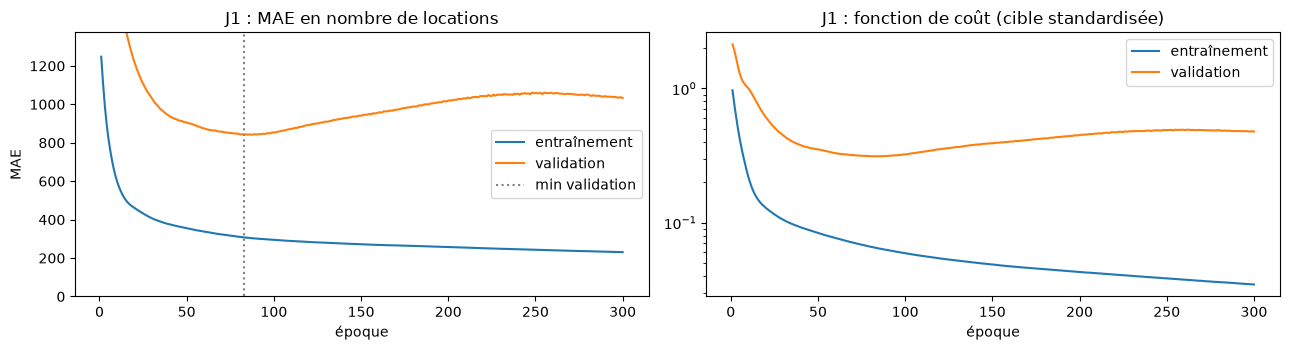

J1 | 16 | 561 param. | perte MSE | rég. aucune
   MAE train = 230.7 | MAE val = 1033.2 (min 841.3 à l'époque 83/300, bruit des 10 dernières époques ±2.1) | écart val/train = 4.48 | 28 s


In [16]:
EPOCHS_J, BATCH_J = 300, 32   # petit jeu : plus d'époques, petits lots
essai("J1", DJ, couches=(16,), epochs=EPOCHS_J, batch=BATCH_J);

**Diagnostic J1 : sur-apprentissage.** L'entraînement baisse sans arrêt (231 à la fin). La validation descend à 841 à l'époque 83, puis remonte à 1 033 : le réseau apprend des détails propres aux jours d'entraînement. Il bat quand même largement la référence (1 033 contre 2 823).

**J2 : trois couches de 256 neurones (140 545 paramètres).** Seule la taille change.

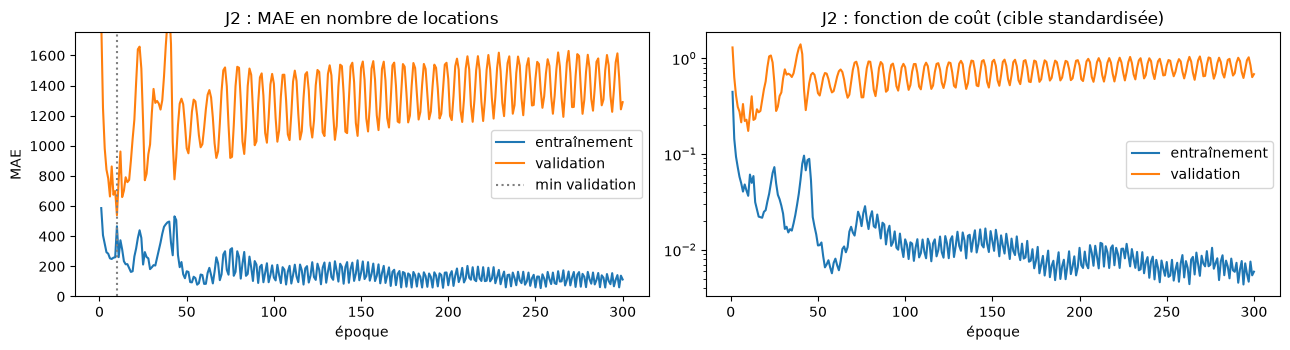

J2 | 256-256-256 | 140545 param. | perte MSE | rég. aucune
   MAE train = 113.0 | MAE val = 1290.0 (min 539.3 à l'époque 10/300, bruit des 10 dernières époques ±141.1) | écart val/train = 11.42 | 32 s


In [17]:
essai("J2", DJ, couches=(256, 256, 256), epochs=EPOCHS_J, batch=BATCH_J);

**Diagnostic J2 : sur-apprentissage fort et instable.** L'entraînement descend à 113, mais la validation finit à 1 290, pire que J1 (écart val/train 11,4). Elle oscille entre environ 900 et 1 600 après l'époque 50 : avec autant de paramètres, des lots de 32 et 547 exemples, chaque pas de gradient change beaucoup la fonction apprise. Son meilleur point (539) arrive dès l'époque 10.

**J3 : J2 avec arrêt précoce** (patience 30, retour aux poids de la meilleure époque).

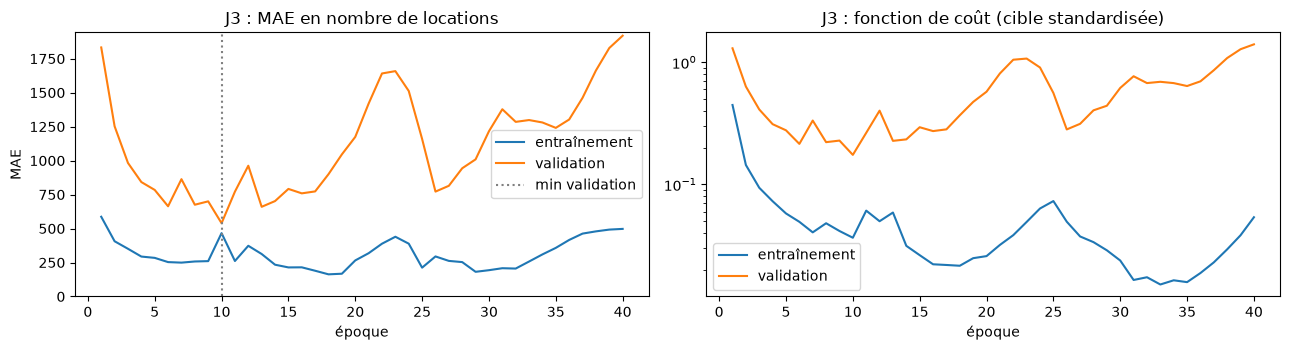

J3 | 256-256-256 | 140545 param. | perte MSE | rég. arrêt précoce (p=30)
   MAE train = 466.2 | MAE val = 539.3 (min 539.3 à l'époque 10/40, bruit des 10 dernières époques ±235.8) | écart val/train = 1.16 | 4 s


In [18]:
depuis("J2", "J3", arret=True, patience=30);

**Diagnostic J3 : corrigé, mais fragile.** Arrêt à l'époque 40, poids de l'époque 10 : la validation tombe à 539, contre 1 290 (écart val/train 1,16). Mais l'entraînement (466) reste deux fois plus haut que pour J1 : le réseau est arrêté avant d'avoir bien appris. Et l'époque 10 est un creux isolé (dès l'époque 11, la validation repasse au-dessus de 750). Choisi sur la validation, ce score est optimiste ; l'acte 3 dira ce qu'il vaut.

### Choix du modèle journalier

J'applique la même règle de choix que dans l'acte 2 : meilleure MAE de validation à 2 % près, puis le moins de paramètres.

In [19]:
ID_JOUR = choisir(["J1", "J2", "J3"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
J3,journalier,256-256-256,140545,MSE,arrêt précoce (p=30),466.23,539.30,539.30,1.16,10,235.77
J1,journalier,16,561,MSE,aucune,230.69,1033.23,841.27,4.48,83,2.08
J2,journalier,256-256-256,140545,MSE,aucune,112.96,1290.02,539.30,11.42,10,141.12


Meilleure MAE val : 539.30. Seuil à 2% : 550.09. Candidats sous le seuil : ['J3'].
=> je retiens J3 (256-256-256, 140545 paramètres).


**Bilan de l'acte 1.** J3 est le seul sous le seuil : je le retiens pour l'acte 3. Avec 547 exemples, les trois réseaux sur-apprennent ; l'arrêt précoce limite les dégâts mais ne remplace pas des données. Je passe au jeu horaire, 24 fois plus grand.

## 6. Acte 2, jeu horaire : modèle de référence

Trois références naïves fixent le score à battre : la médiane du train, la moyenne du train, et la moyenne du train par heure, qui ne connaît que l'heure.

In [20]:
d = D[None]
med_h, moy_h = np.median(d.y["train"]), d.y["train"].mean()
moy_par_heure = hour[hour.jeu == "train"].groupby("hr").cnt.mean()

def refs_horaires(j):
    y = D[None].y[j]
    heures = hour.loc[D[None].masques[j], "hr"]
    return {"médiane du train": mae(y, np.full(len(y), med_h)),
            "moyenne du train": mae(y, np.full(len(y), moy_h)),
            "moyenne du train par heure": mae(y, heures.map(moy_par_heure).to_numpy())}

REF_H = pd.Series(refs_horaires("val"), name="MAE val (loc./heure)").round(1)
REF_H.to_frame()

,MAE val (loc./heure)
médiane du train,213.7
moyenne du train,197.8
moyenne du train par heure,136.7


**Références horaires.** Médiane : 214 vélos par heure d'erreur ; moyenne : 198. Connaître seulement l'heure fait tomber l'erreur à 137 : c'est le score qu'un MLP doit battre.

## 7. Acte 2 : itérations selon le protocole

Je change **un seul paramètre principal à la fois** : 1. variables d'entrée, 2. profondeur, 3. largeur, 4. fonction de coût, 5. régularisation. Tout le reste ne bouge pas, donc chaque écart vient du paramètre changé. À chaque étape, j'applique la règle de choix et je repars de la configuration retenue. Tous les essais sont comparés sur la **MAE de validation en vélos par heure**.

### Étape 1 : variables d'entrée et encodage de l'heure

Architecture fixe : 2 couches de 32 neurones, perte MSE (moyenne des erreurs au carré), sans régularisation.

**H1 : sans l'heure** (calendrier et météo seulement).

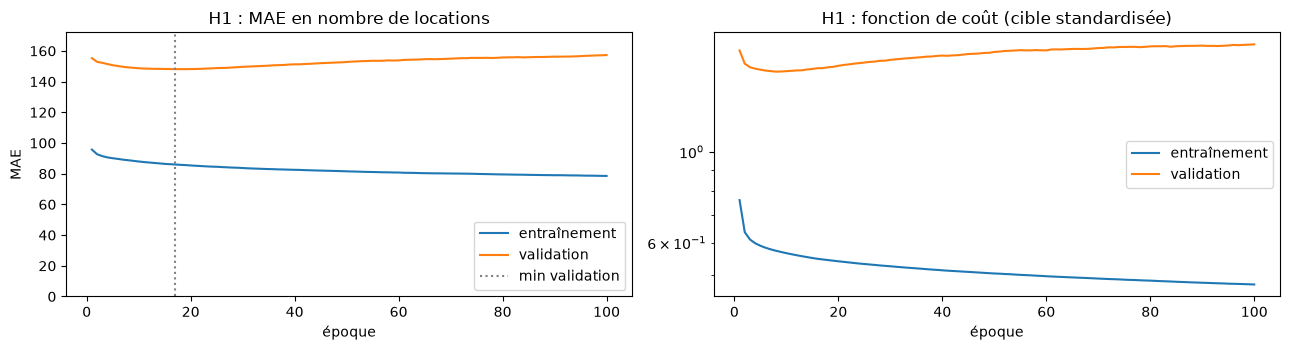

H1 | 32-32 | 2209 param. | perte MSE | rég. aucune
   MAE train = 78.5 | MAE val = 157.3 (min 148.1 à l'époque 17/100, bruit des 10 dernières époques ±0.4) | écart val/train = 2.00 | 17 s


In [21]:
essai("H1", D[None], couches=(32, 32));

**Diagnostic H1 : sous-apprentissage par manque d'information.** Même l'entraînement reste haut (78,5) : le réseau ne distingue pas 4 h de 17 h. La validation finit à 157 (minimum 148 à l'époque 17). C'est mieux que la moyenne constante (198), mais **moins bien que la simple moyenne par heure (137)**.

**H2 : heure brute** (`hr` standardisée). Pour le réseau, 23 h et 0 h sont alors très éloignées.

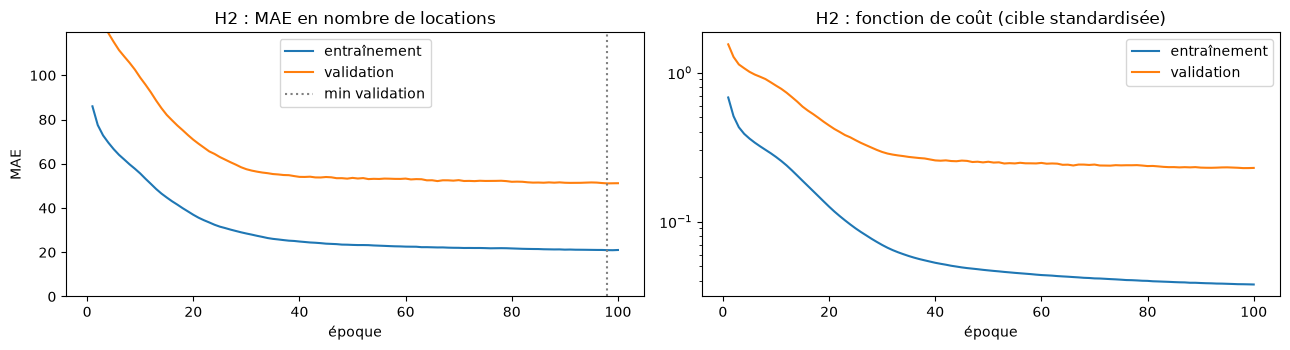

H2 | 32-32 | 2241 param. | perte MSE | rég. aucune
   MAE train = 21.0 | MAE val = 51.2 (min 51.1 à l'époque 98/100, bruit des 10 dernières époques ±0.1) | écart val/train = 2.44 | 17 s


In [22]:
depuis("H1", "H2", data=D["brut"]);

**Diagnostic H2 : bon compromis, pas tout à fait convergé.** Une seule colonne fait passer la validation de 157 à 51 : l'erreur est divisée par 3. L'entraînement descend à 21 et la validation baisse encore à l'époque 98. L'écart val/train (2,44) vient surtout du niveau plus haut de la validation (288 contre 168 vélos par heure) : les courbes ne remontent pas.

**H3 : heure en one-hot** (24 colonnes) : un niveau propre à chaque heure.

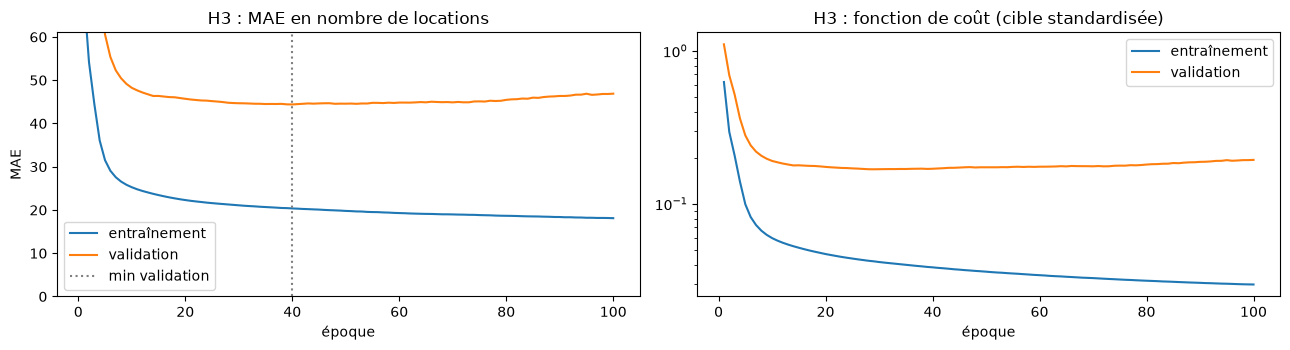

H3 | 32-32 | 2977 param. | perte MSE | rég. aucune
   MAE train = 18.1 | MAE val = 46.9 (min 44.4 à l'époque 40/100, bruit des 10 dernières époques ±0.2) | écart val/train = 2.59 | 17 s


In [23]:
depuis("H1", "H3", data=D["onehot"]);

**Diagnostic H3 : bon compromis, léger sur-apprentissage en fin de course.** La validation descend à 44,4 (époque 40), puis remonte doucement à 46,9 pendant que l'entraînement baisse (18,1). C'est la meilleure des quatre variantes.

**H4 : heure en sinus / cosinus** : l'heure placée sur un cercle, 23 h et 0 h deviennent voisines.

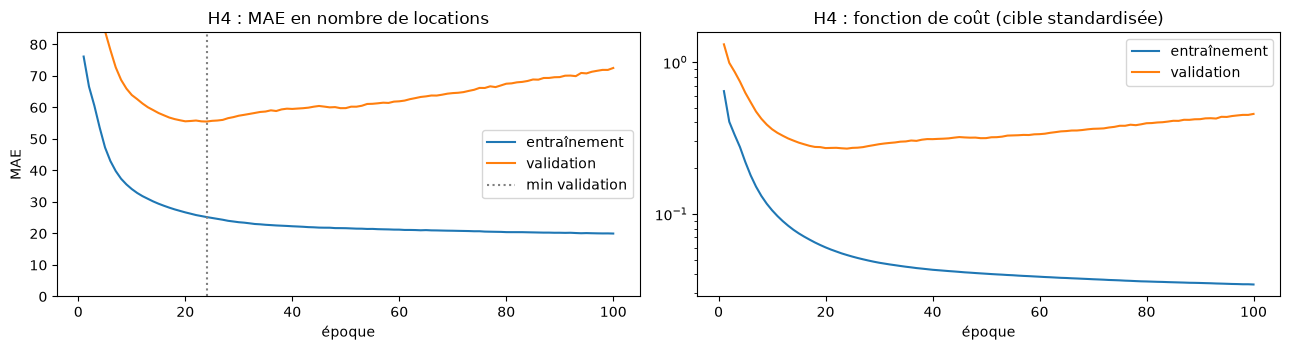

H4 | 32-32 | 2273 param. | perte MSE | rég. aucune
   MAE train = 20.0 | MAE val = 72.5 (min 55.5 à l'époque 24/100, bruit des 10 dernières époques ±0.8) | écart val/train = 3.63 | 17 s


In [24]:
depuis("H1", "H4", data=D["sincos"]);

**Diagnostic H4 : sur-apprentissage net, contraire à mon attente.** La validation atteint 55,5 à l'époque 24, puis remonte jusqu'à 72,5, alors que l'entraînement reste vers 20 : c'est moins bien que l'heure brute (51,2). Mon hypothèse, non vérifiée : avec deux coordonnées, le réseau construit les deux pics étroits par des combinaisons fines, qui se transposent mal à l'été 2012.

**Bilan de l'étape 1.**

In [25]:
ID_E1 = choisir(["H1", "H2", "H3", "H4"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
H3,heure one-hot,32-32,2977,MSE,aucune,18.11,46.89,44.39,2.59,40,0.17
H2,heure brute,32-32,2241,MSE,aucune,21.02,51.22,51.14,2.44,98,0.14
H4,heure sin/cos,32-32,2273,MSE,aucune,19.98,72.53,55.52,3.63,24,0.85
H1,sans heure,32-32,2209,MSE,aucune,78.54,157.30,148.10,2.00,17,0.36


Meilleure MAE val : 46.89. Seuil à 2% : 47.83. Candidats sous le seuil : ['H3'].
=> je retiens H3 (32-32, 2977 paramètres).


L'heure divise l'erreur par 3 (de 157 à 47-51), et l'encodage compte : one-hot 46,9, brute 51,2, sinus/cosinus 72,5. **Je garde le one-hot (H3).**

### Étape 2 : profondeur

Avec 32 neurones par couche, je teste 1, 2 (déjà fait), 3 et 4 couches cachées.

**P1 : une couche de 32 neurones.**

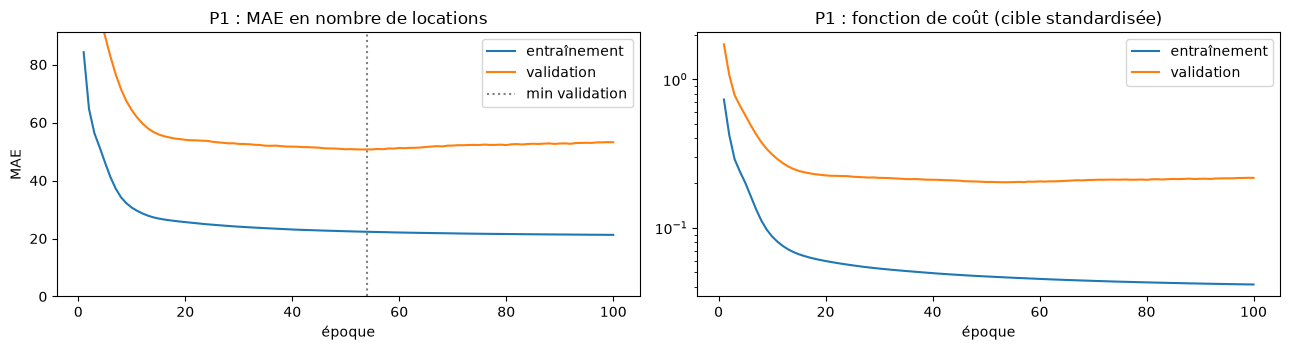

P1 | 32 | 1921 param. | perte MSE | rég. aucune
   MAE train = 21.3 | MAE val = 53.2 (min 50.7 à l'époque 54/100, bruit des 10 dernières époques ±0.2) | écart val/train = 2.50 | 17 s


In [26]:
depuis(ID_E1, "P1", couches=(32,));

**Diagnostic P1 : léger sous-apprentissage.** Avec une seule couche, l'entraînement reste plus haut (21,3 contre 18,1 pour H3) et la validation aussi (53,2 contre 46,9). Une couche ne suffit pas à bien combiner l'heure avec le type de jour et la météo.

**P3 : trois couches de 32 neurones.**

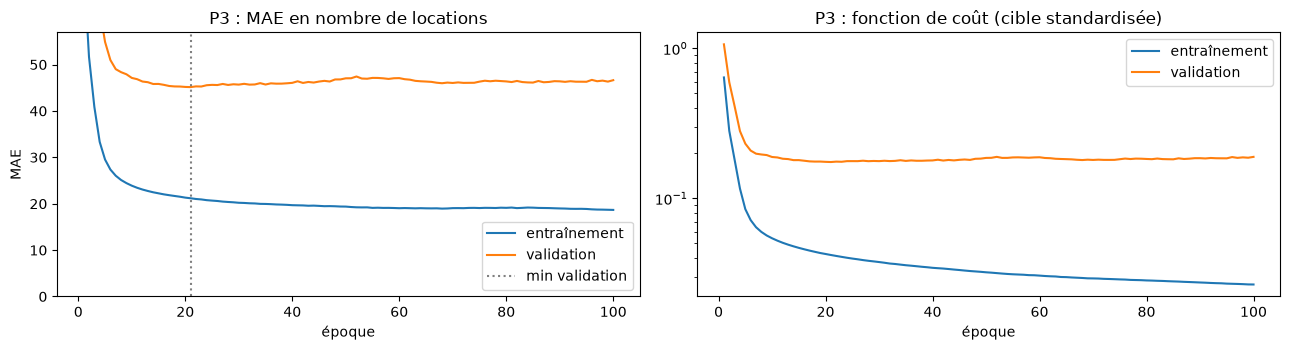

P3 | 32-32-32 | 4033 param. | perte MSE | rég. aucune
   MAE train = 18.7 | MAE val = 46.6 (min 45.1 à l'époque 21/100, bruit des 10 dernières époques ±0.1) | écart val/train = 2.50 | 19 s


In [27]:
depuis(ID_E1, "P3", couches=(32, 32, 32));

**Diagnostic P3 : bon compromis, léger sur-apprentissage.** Trois couches donnent 46,6 en validation, contre 46,9 pour deux couches : la différence est minuscule. Le minimum (45,1) arrive plus tôt, à l'époque 21, puis la validation remonte un peu.

**P4 : quatre couches de 32 neurones.**

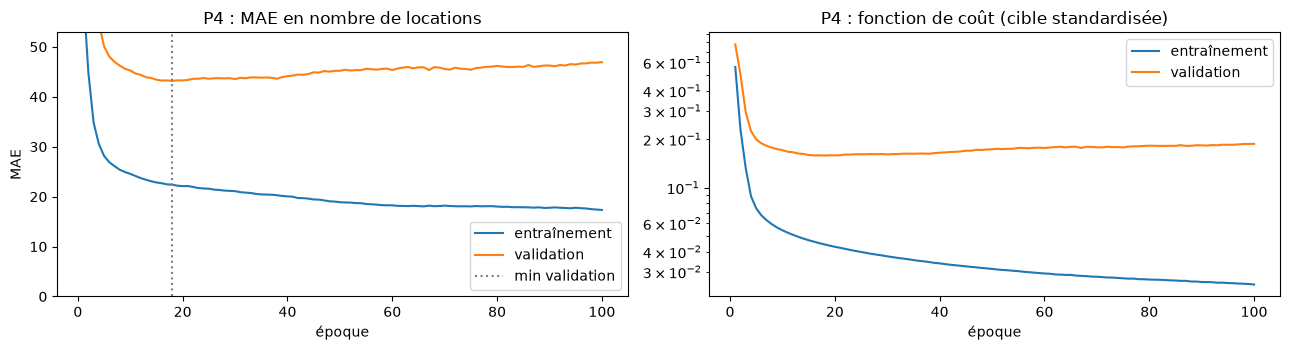

P4 | 32-32-32-32 | 5089 param. | perte MSE | rég. aucune
   MAE train = 17.3 | MAE val = 46.9 (min 43.2 à l'époque 18/100, bruit des 10 dernières époques ±0.3) | écart val/train = 2.71 | 18 s


In [28]:
depuis(ID_E1, "P4", couches=(32, 32, 32, 32));

**Diagnostic P4 : sur-apprentissage.** Avec quatre couches, l'entraînement est le plus bas de l'étape (17,3), mais la validation (46,9) n'est pas meilleure. Le minimum (43,2) arrive dès l'époque 18, puis la validation remonte. Plus de profondeur aide le réseau à coller à l'entraînement, pas à généraliser.

In [29]:
ID_E2 = choisir(["P1", ID_E1, "P3", "P4"])
PROF = len(CONFIGS[ID_E2]["couches"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
P3,heure one-hot,32-32-32,4033,MSE,aucune,18.66,46.63,45.14,2.50,21,0.14
H3,heure one-hot,32-32,2977,MSE,aucune,18.11,46.89,44.39,2.59,40,0.17
P4,heure one-hot,32-32-32-32,5089,MSE,aucune,17.33,46.93,43.17,2.71,18,0.26
P1,heure one-hot,32,1921,MSE,aucune,21.26,53.19,50.71,2.50,54,0.17


Meilleure MAE val : 46.63. Seuil à 2% : 47.56. Candidats sous le seuil : ['H3', 'P3', 'P4'].
=> je retiens H3 (32-32, 2977 paramètres).


**Bilan de l'étape 2.** Deux, trois et quatre couches sont à moins de 2 % (46,6 à 46,9), une seule couche est moins bonne. La parcimonie garde **deux couches (H3)**.

### Étape 3 : largeur

Avec deux couches, je teste 16, 32 (déjà fait), 64, 128 et 256 neurones par couche.

**L16 : deux couches de 16 neurones.**

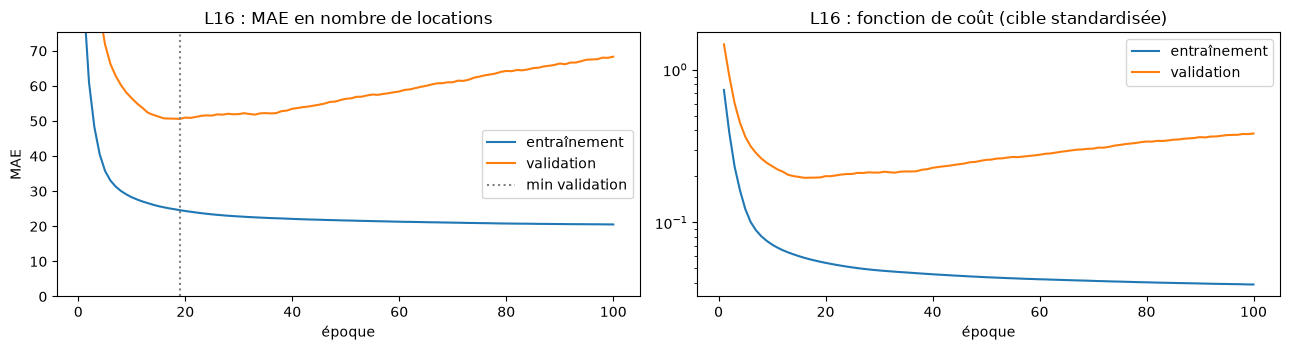

L16 | 16-16 | 1233 param. | perte MSE | rég. aucune
   MAE train = 20.5 | MAE val = 68.3 (min 50.6 à l'époque 19/100, bruit des 10 dernières époques ±0.7) | écart val/train = 3.33 | 17 s


In [30]:
depuis(ID_E2, "L16", couches=(16,) * PROF);

**Diagnostic L16 : sur-apprentissage, malgré la petite taille.** J'attendais du sous-apprentissage. En fait, l'entraînement descend (20,5) et la validation atteint 50,6 à l'époque 19 avant de remonter jusqu'à 68,3. Comme pour H4, le réseau se spécialise sur la période d'entraînement : être petit ne protège pas du sur-apprentissage.

**L64 : deux couches de 64 neurones.**

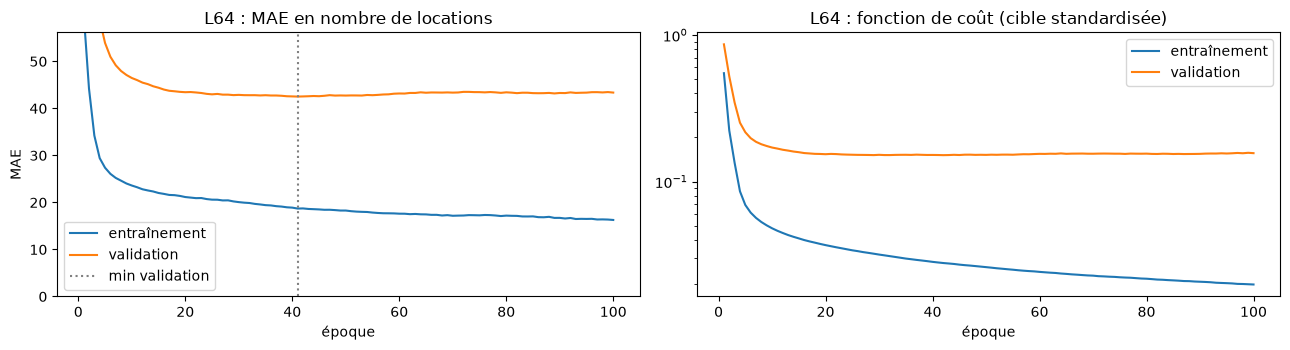

L64 | 64-64 | 8001 param. | perte MSE | rég. aucune
   MAE train = 16.3 | MAE val = 43.4 (min 42.5 à l'époque 41/100, bruit des 10 dernières époques ±0.1) | écart val/train = 2.66 | 18 s


In [31]:
depuis(ID_E2, "L64", couches=(64,) * PROF);

**Diagnostic L64 : bon compromis, le meilleur de l'étape.** La validation descend à 42,5 (époque 41) et reste ensuite presque plate (43,4 à la fin, bruit ±0,1). L'entraînement continue de baisser doucement (16,3). C'est la courbe la plus stable vue jusqu'ici : la largeur supplémentaire aide le réseau à apprendre sans dériver.

**L128 : deux couches de 128 neurones** (environ 24 000 paramètres pour 13 003 heures d'entraînement).

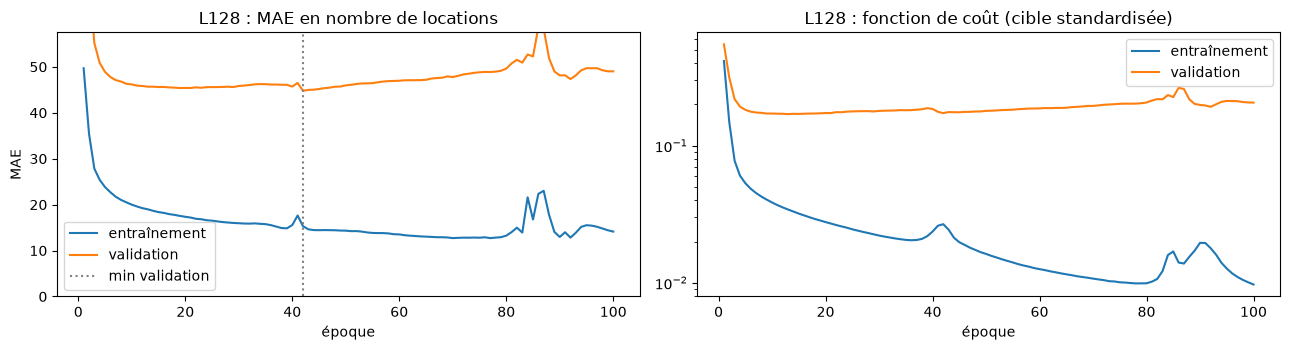

L128 | 128-128 | 24193 param. | perte MSE | rég. aucune
   MAE train = 14.1 | MAE val = 49.0 (min 44.8 à l'époque 42/100, bruit des 10 dernières époques ±0.8) | écart val/train = 3.47 | 19 s


In [32]:
depuis(ID_E2, "L128", couches=(128,) * PROF);

**Diagnostic L128 : sur-apprentissage.** L'entraînement descend encore (14,1) mais la validation remonte : 44,8 au mieux, 49,0 à la fin. L'écart val/train passe à 3,47. Doubler la largeur par rapport à L64 triple les paramètres et dégrade la validation.

**L256 : deux couches de 256 neurones** (environ 81 000 paramètres).

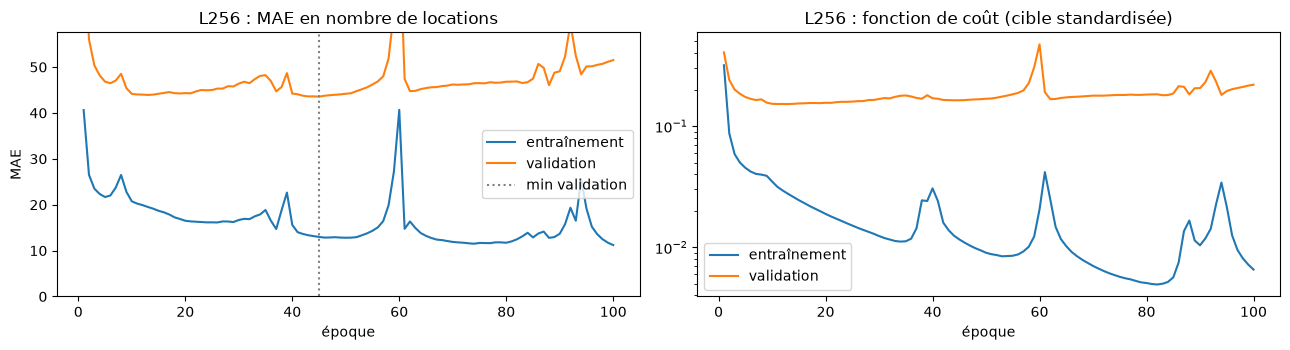

L256 | 256-256 | 81153 param. | perte MSE | rég. aucune
   MAE train = 11.2 | MAE val = 51.5 (min 43.5 à l'époque 45/100, bruit des 10 dernières époques ±2.8) | écart val/train = 4.60 | 23 s


In [33]:
depuis(ID_E2, "L256", couches=(256,) * PROF);

**Diagnostic L256 : sur-apprentissage fort et instable.** L'entraînement atteint le plus bas niveau de l'acte 2 (11,2), mais la validation finit à 51,5 (écart val/train 4,6). Des pics brusques apparaissent (époques 40, 60 et 92) et le bruit final vaut ±2,8 : avec 81 000 paramètres, le pas d'Adam devient trop grand par moments.

In [34]:
ID_E3 = choisir([ID_E2, "L16", "L64", "L128", "L256"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
L64,heure one-hot,64-64,8001,MSE,aucune,16.27,43.36,42.51,2.66,41,0.07
H3,heure one-hot,32-32,2977,MSE,aucune,18.11,46.89,44.39,2.59,40,0.17
L128,heure one-hot,128-128,24193,MSE,aucune,14.13,49.02,44.77,3.47,42,0.76
L256,heure one-hot,256-256,81153,MSE,aucune,11.20,51.51,43.54,4.60,45,2.82
L16,heure one-hot,16-16,1233,MSE,aucune,20.53,68.33,50.61,3.33,19,0.66


Meilleure MAE val : 43.36. Seuil à 2% : 44.23. Candidats sous le seuil : ['L64'].
=> je retiens L64 (64-64, 8001 paramètres).


**Bilan de l'étape 3.** Optimum net à 64 neurones (43,4) : 16 neurones (68,3) et 128-256 (49,0-51,5) font moins bien. **Je garde deux couches de 64 neurones (8 001 paramètres).** C'est la courbe en U classique entre trop peu et trop de capacité.

### Étape 4 : fonction de coût

Même architecture ; seule change la perte minimisée à l'entraînement : **MSE** (déjà fait, erreurs au carré), **MAE** (erreurs absolues, la métrique imposée) ou **Huber** (comme la MSE pour les petites erreurs, comme la MAE pour les grandes ; `delta = 1` vaut ici environ 161 vélos par heure). Je compare toujours sur la même MAE de validation.

**F_MAE : perte MAE**, à la place de la MSE.

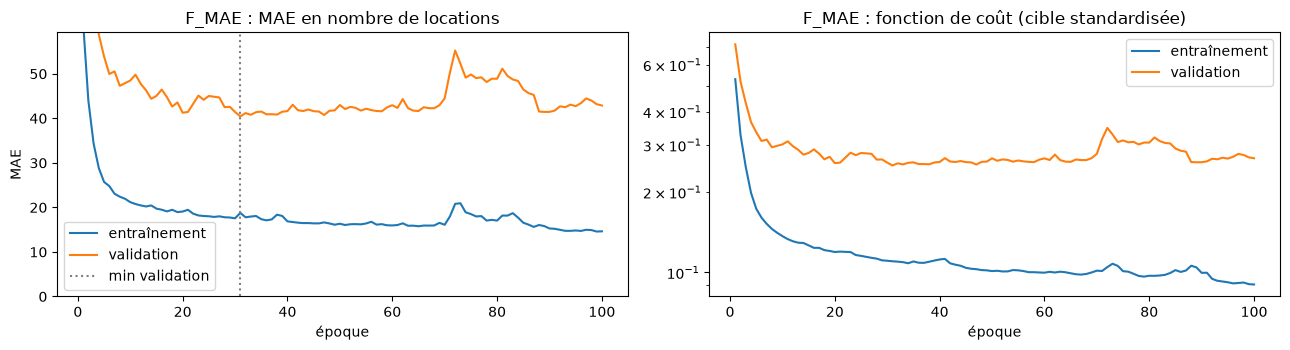

F_MAE | 64-64 | 8001 param. | perte MAE | rég. aucune
   MAE train = 14.6 | MAE val = 42.9 (min 40.4 à l'époque 31/100, bruit des 10 dernières époques ±0.7) | écart val/train = 2.93 | 18 s


In [35]:
depuis(ID_E3, "F_MAE", perte="mae");

**Diagnostic F_MAE : bon compromis, validation plus agitée.** Validation finale à 42,9 contre 43,4 avec la MSE ; minimum à 40,4 (époque 31) contre 42,5. L'entraînement descend plus bas (14,6), mais la validation est bien plus agitée (pic vers 55 à l'époque 72). Le gradient de la MAE garde la même taille quelle que soit l'erreur : les poids continuent de bouger près du minimum. Le gain final (0,5 vélo par heure) est plus petit que ces variations.

**F_HUB : perte de Huber** (`delta = 1`).

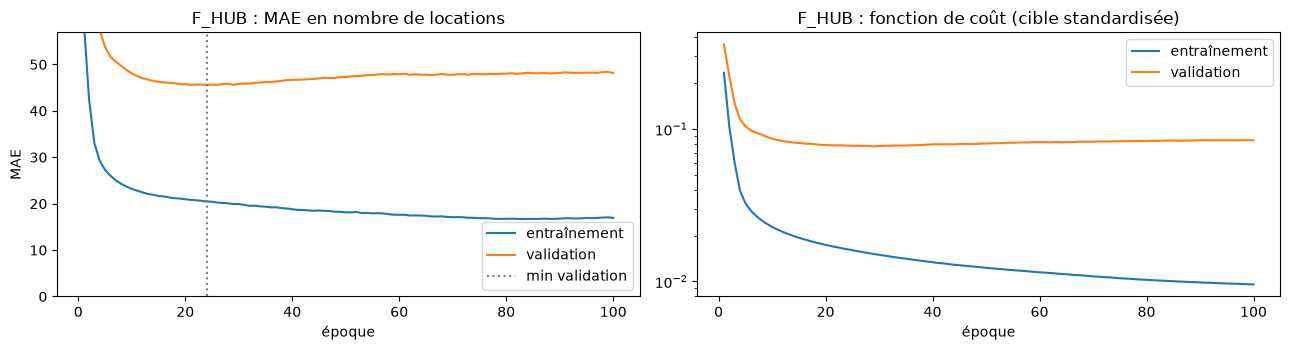

F_HUB | 64-64 | 8001 param. | perte Huber (delta=1) | rég. aucune
   MAE train = 16.9 | MAE val = 48.2 (min 45.6 à l'époque 24/100, bruit des 10 dernières époques ±0.1) | écart val/train = 2.84 | 18 s


In [36]:
depuis(ID_E3, "F_HUB", perte="huber");

**Diagnostic F_HUB : moins bon que les deux autres.** Validation à 48,2 (minimum 45,6 à l'époque 24, puis légère remontée). Je ne l'attendais pas : avec `delta = 1`, presque toutes les erreurs sont « petites », et Huber devrait ressembler à la MSE. Mesuré sur une seule graine, cet écart peut relever du bruit, et je n'ai pas testé d'autre valeur de `delta`.

In [37]:
ID_E4 = choisir([ID_E3, "F_MAE", "F_HUB"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
F_MAE,heure one-hot,64-64,8001,MAE,aucune,14.63,42.88,40.42,2.93,31,0.73
L64,heure one-hot,64-64,8001,MSE,aucune,16.27,43.36,42.51,2.66,41,0.07
F_HUB,heure one-hot,64-64,8001,Huber (delta=1),aucune,16.95,48.16,45.58,2.84,24,0.07


Meilleure MAE val : 42.88. Seuil à 2% : 43.74. Candidats sous le seuil : ['F_MAE', 'L64'].
=> je retiens F_MAE (64-64, 8001 paramètres).


**Bilan de l'étape 4.** MAE (42,9) et MSE (43,4) sont sous le seuil avec autant de paramètres : la règle garde **la perte MAE (F_MAE)**, cohérente avec la métrique. L'écart est dans le bruit, et la MAE agite la validation : l'arrêt précoce y répond à l'étape suivante.

### Étape 5 : régularisation

Quatre techniques contre le sur-apprentissage, une à la fois, sur F_MAE : **arrêt précoce** (patience 20, retour aux meilleurs poids), **dropout 0,2** (20 % des neurones éteints au hasard), **L2 1e-4** (pénalité sur la taille des poids) et **réduction de capacité** (moitié moins de neurones). L'arrêt précoce choisit l'époque sur la validation : son score est un peu optimiste, et le test corrigera ce biais.

**R_ES : arrêt précoce.**

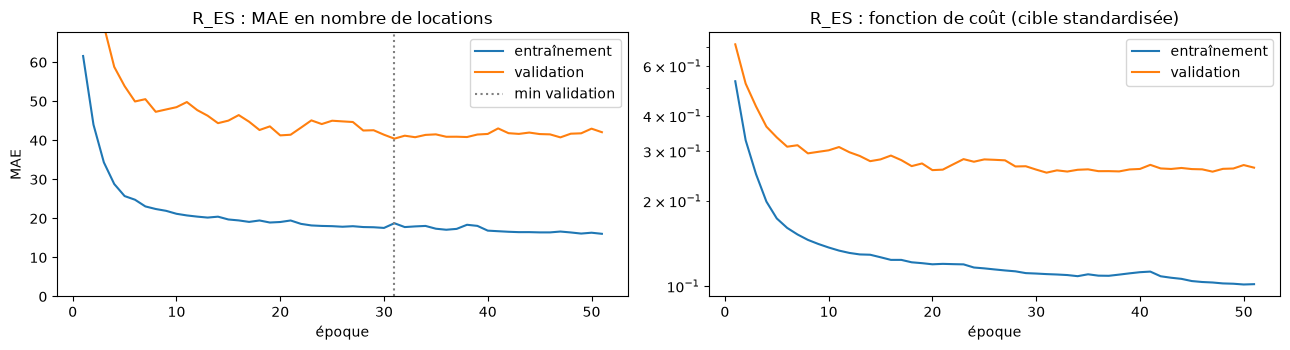

R_ES | 64-64 | 8001 param. | perte MAE | rég. arrêt précoce (p=20)
   MAE train = 18.8 | MAE val = 40.4 (min 40.4 à l'époque 31/51, bruit des 10 dernières époques ±0.5) | écart val/train = 2.15 | 9 s


In [38]:
depuis(ID_E4, "R_ES", arret=True);

**Diagnostic R_ES : c'est F_MAE arrêté à sa meilleure époque.** Avec la même graine et les mêmes données, les courbes sont identiques jusqu'à l'arrêt, à l'époque 51, avec les poids de l'époque 31. La validation vaut 40,4, le minimum de F_MAE, contre 42,9 à sa dernière époque ; l'écart val/train passe de 2,93 à 2,15. L'arrêt précoce n'apprend pas mieux : il garde le meilleur moment, et divise le temps d'entraînement par deux.

**R_DO : dropout 0,2**, sans arrêt précoce.

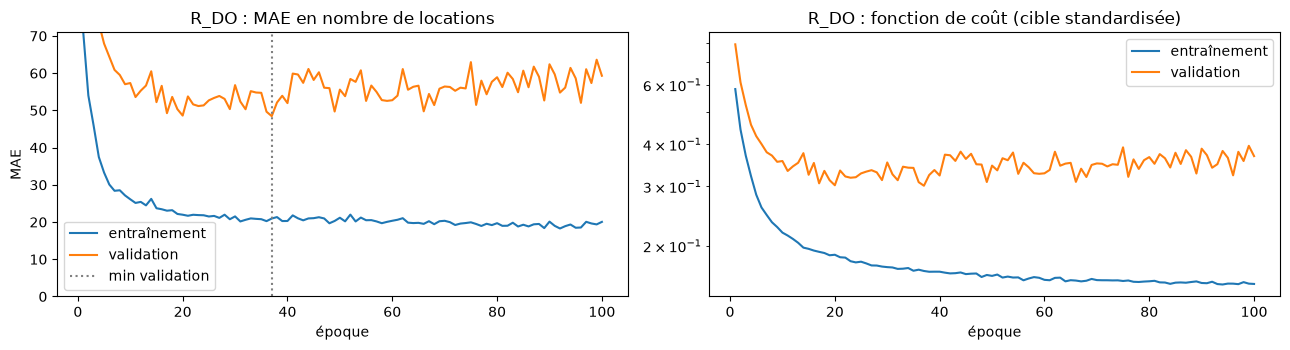

R_DO | 64-64 | 8001 param. | perte MAE | rég. dropout 0.2
   MAE train = 20.0 | MAE val = 59.3 (min 48.4 à l'époque 37/100, bruit des 10 dernières époques ±3.3) | écart val/train = 2.96 | 20 s


In [39]:
depuis(ID_E4, "R_DO", dropout=0.2);

**Diagnostic R_DO : le dropout dégrade le modèle.** Validation à 59,3 en fin d'entraînement (minimum 48,4), contre 42,9 sans dropout ; l'entraînement est moins bon (20,0 contre 14,6) et la validation agitée (bruit ±3,3). Le bruit du dropout s'ajoute à celui de la perte MAE, sur un réseau qui ne sur-apprenait pas assez fort pour en profiter. Même à sa meilleure époque (48,4), il reste derrière F_MAE (40,4).

**R_L2 : pénalité L2 (1e-4)**, sans arrêt précoce.

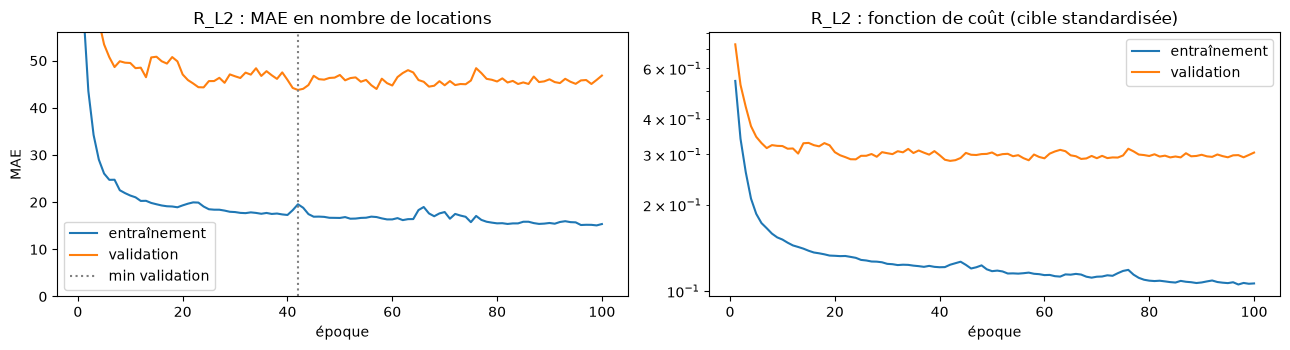

R_L2 | 64-64 | 8001 param. | perte MAE | rég. L2 0.0001
   MAE train = 15.4 | MAE val = 46.8 (min 43.8 à l'époque 42/100, bruit des 10 dernières époques ±0.5) | écart val/train = 3.05 | 17 s


In [40]:
depuis(ID_E4, "R_L2", l2=1e-4);

**Diagnostic R_L2 : la L2 n'aide pas ici.** Validation à 46,8 (minimum 43,8), contre 42,9 sans régularisation, avec une remontée en fin de course. Je n'ai testé qu'une valeur ; une pénalité plus forte pourrait se comporter autrement.

**R_CAP : réduction de capacité** (deux couches de 32 neurones).

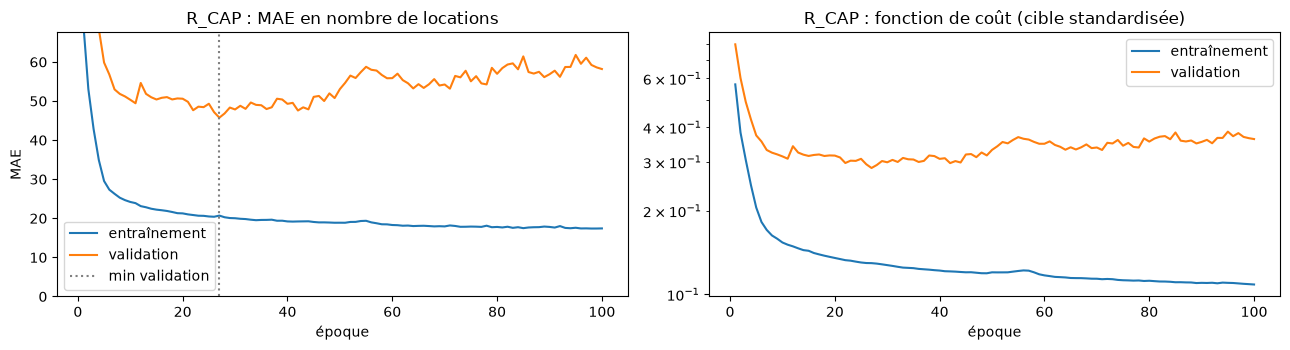

R_CAP | 32-32 | 2977 param. | perte MAE | rég. aucune
   MAE train = 17.4 | MAE val = 58.2 (min 45.8 à l'époque 27/100, bruit des 10 dernières époques ±1.5) | écart val/train = 3.34 | 17 s


In [41]:
# Réduction de capacité : moitié moins de neurones par couche
largeur = CONFIGS[ID_E4]["couches"][0]
depuis(ID_E4, "R_CAP", couches=(max(8, largeur // 2),) * PROF);

**Diagnostic R_CAP : réduire la capacité dégrade la validation.** Avec 32 neurones par couche, la validation finit à 58,2 (minimum 45,8 à l'époque 27) : comme L16, le réseau étroit dérive sur ce découpage. Même à sa meilleure époque, il reste derrière F_MAE (40,4).

### Comparaison équitable avec l'arrêt précoce

R_ES est jugé à sa meilleure époque, le dropout et la L2 à leur dernière. Pour comparer au même critère, j'ajoute la colonne « min MAE val » et je refais ces deux essais avec le même arrêt précoce.

**R_DO_ES : dropout 0,2 + arrêt précoce.**

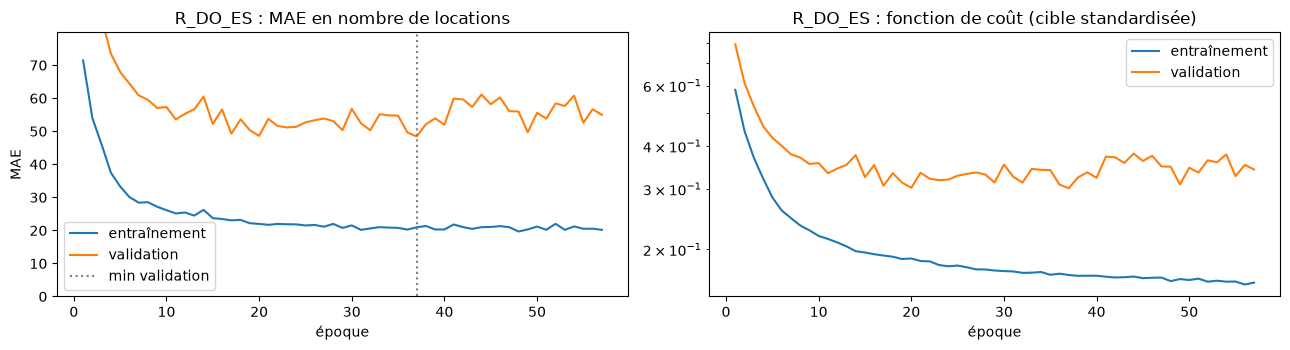

R_DO_ES | 64-64 | 8001 param. | perte MAE | rég. dropout 0.2, arrêt précoce (p=20)
   MAE train = 20.9 | MAE val = 48.4 (min 48.4 à l'époque 37/57, bruit des 10 dernières époques ±3.0) | écart val/train = 2.31 | 11 s


In [42]:
depuis("R_DO", "R_DO_ES", arret=True);

**Diagnostic R_DO_ES : toujours derrière.** Arrêt à l'époque 57, poids de l'époque 37 : la validation vaut 48,4, exactement le minimum de R_DO, ce qui confirme que l'arrêt précoce ne fait que choisir l'époque. Le dropout reste nettement derrière R_ES (48,4 contre 40,4), avec une validation agitée (bruit ±3,0).

**R_L2_ES : L2 1e-4 + arrêt précoce.**

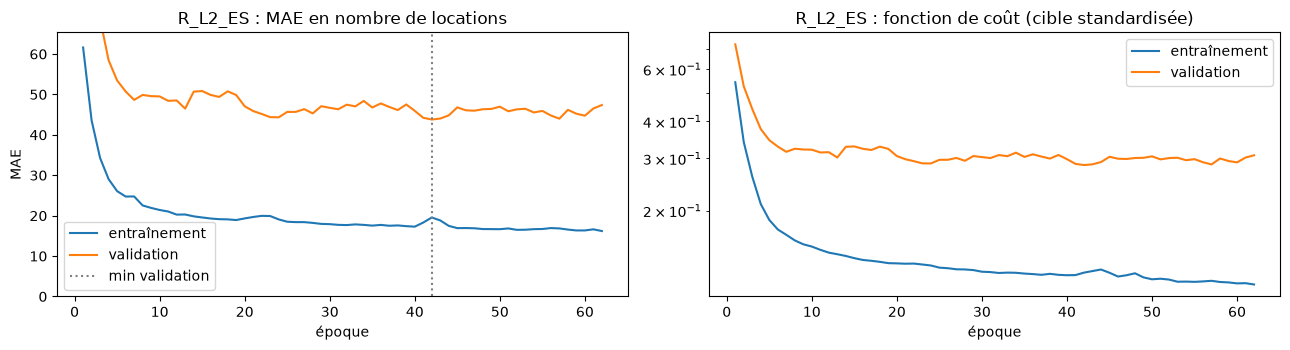

R_L2_ES | 64-64 | 8001 param. | perte MAE | rég. L2 0.0001, arrêt précoce (p=20)
   MAE train = 19.6 | MAE val = 43.8 (min 43.8 à l'époque 42/62, bruit des 10 dernières époques ±1.0) | écart val/train = 2.24 | 11 s


In [43]:
depuis("R_L2", "R_L2_ES", arret=True);

**Diagnostic R_L2_ES : bon compromis, moins bon que R_ES.** Arrêt à l'époque 62, poids de l'époque 42 : la validation vaut 43,8, le minimum de R_L2 (écart val/train 2,24, proche des 2,15 de R_ES). À critère égal, la L2 reste derrière : 43,8 contre 40,4.

In [44]:
ID_E5 = choisir([ID_E4, "R_ES", "R_DO", "R_L2", "R_CAP", "R_DO_ES", "R_L2_ES"])

,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
R_ES,heure one-hot,64-64,8001,MAE,arrêt précoce (p=20),18.77,40.42,40.42,2.15,31,0.53
F_MAE,heure one-hot,64-64,8001,MAE,aucune,14.63,42.88,40.42,2.93,31,0.73
R_L2_ES,heure one-hot,64-64,8001,MAE,"L2 0.0001, arrêt précoce (p=20)",19.55,43.79,43.79,2.24,42,0.96
R_L2,heure one-hot,64-64,8001,MAE,L2 0.0001,15.36,46.84,43.79,3.05,42,0.52
R_DO_ES,heure one-hot,64-64,8001,MAE,"dropout 0.2, arrêt précoce (p=20)",20.95,48.45,48.45,2.31,37,2.97
R_CAP,heure one-hot,32-32,2977,MAE,aucune,17.42,58.19,45.75,3.34,27,1.51
R_DO,heure one-hot,64-64,8001,MAE,dropout 0.2,20.05,59.31,48.45,2.96,37,3.26


Meilleure MAE val : 40.42. Seuil à 2% : 41.23. Candidats sous le seuil : ['R_ES'].
=> je retiens R_ES (64-64, 8001 paramètres).


**Bilan de l'étape 5.** Au même critère, la meilleure époque :

| Essai | Dernière époque | Meilleure époque |
| --- | --- | --- |
| F_MAE (sans régularisation) | 42,9 | 40,4 |
| L2 1e-4 | 46,8 | 43,8 |
| Réduction de capacité (32-32) | 58,2 | 45,8 |
| Dropout 0,2 | 59,3 | 48,4 |

**Le dropout, la L2 et la réduction de capacité font moins bien que le modèle sans régularisation**, avec ou sans arrêt précoce. R_ES (40,4) est le seul sous le seuil : il sert de point de départ à la recherche automatique.

## 8. Acte 2 : recherche d'hyper-paramètres avec Keras Tuner (HyperBand)

Pour vérifier mes choix manuels, je lance une recherche automatique autour de R_ES. HyperBand essaie beaucoup de configurations pendant peu d'époques, puis entraîne plus longtemps les meilleures.

- **Espace** (81 combinaisons) : profondeur retenue ±1 couche ; largeur retenue, sa moitié ou son double ; dropout 0, 0,1 ou 0,2 ; taux d'apprentissage 3e-4, 1e-3 ou 3e-3.
- **Budget** : 30 époques au maximum par configuration, facteur 3, arrêt précoce à 5 époques.

La meilleure configuration est ensuite réentraînée avec mon protocole complet, pour une comparaison juste.

In [45]:
base = CONFIGS[ID_E5]
d_hp, prof, larg = base["data"], len(base["couches"]), base["couches"][0]
CHOIX_COUCHES = sorted({max(1, prof - 1), prof, prof + 1})
CHOIX_NEURONES = sorted({max(8, larg // 2), larg, larg * 2})
print("Point de départ :", ID_E5, "| couches", CHOIX_COUCHES, "| neurones", CHOIX_NEURONES,
      "| dropout [0, 0.1, 0.2] | lr [3e-4, 1e-3, 3e-3] | perte", base["perte"], "| L2", base["l2"])

def construire_hp(hp):
    n = hp.Choice("couches", CHOIX_COUCHES)
    u = hp.Choice("neurones", CHOIX_NEURONES)
    dr = hp.Choice("dropout", [0.0, 0.1, 0.2])
    lr = hp.Choice("lr", [3e-4, 1e-3, 3e-3])
    return construire_mlp(d_hp.n_in, (u,) * n, base["perte"], dr, base["l2"], lr)

tuner = kt.Hyperband(construire_hp, objective=kt.Objective("val_mae", "min"), max_epochs=30, factor=3,
                     hyperband_iterations=1, seed=SEED, directory="kt_dir", project_name="bike_hour", overwrite=True)
t0 = time.time()
tuner.search(d_hp.X["train"], d_hp.ys["train"], validation_data=(d_hp.X["val"], d_hp.ys["val"]),
             batch_size=BATCH, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_mae", patience=5)])
print(f"Recherche terminée en {time.time() - t0:.0f} s, {len(tuner.oracle.trials)} essais.")

lignes = []
for t in tuner.oracle.get_best_trials(len(tuner.oracle.trials)):
    v = dict(t.hyperparameters.values)
    lignes.append({"couches": v["couches"], "neurones": v["neurones"], "dropout": v["dropout"], "lr": v["lr"],
                   "époques max": v.get("tuner/epochs"), "MAE val (loc./h)": round(t.score * d_hp.sd, 1)})
KT_TOP = pd.DataFrame(lignes)
KT_TOP.head(10)

Point de départ : R_ES | couches [1, 2, 3] | neurones [32, 64, 128] | dropout [0, 0.1, 0.2] | lr [3e-4, 1e-3, 3e-3] | perte mae | L2 0.0


Recherche terminée en 197 s, 90 essais.


,couches,neurones,dropout,lr,époques max,MAE val (loc./h)
0,3,128,0.0,0.003,10,40.8
1,1,128,0.2,0.001,30,41.5
2,3,64,0.0,0.003,10,42.4
3,2,128,0.0,0.003,30,42.9
4,2,32,0.0,0.003,30,43.0
5,1,128,0.1,0.003,30,43.1
6,2,32,0.0,0.003,10,43.3
7,2,128,0.0,0.003,10,43.5
8,3,128,0.0,0.001,10,43.5
9,1,64,0.1,0.003,30,43.8


**Résultat de la recherche.** 90 essais en un peu plus de 3 minutes. Meilleure configuration : 3 couches de 128 neurones, sans dropout, taux 3e-3 (40,8 en validation après 10 époques au plus). Avec un budget court, les grands taux d'apprentissage sont avantagés.

**KT : la meilleure configuration, réentraînée avec mon protocole** (perte MAE, arrêt précoce, 100 époques au plus).

Meilleurs hyper-paramètres : {'couches': 3, 'neurones': 128, 'dropout': 0.0, 'lr': 0.003}


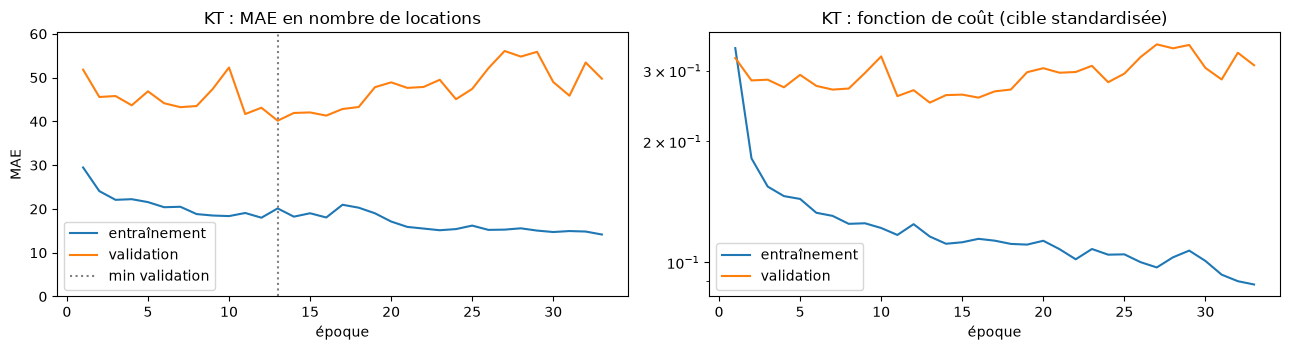

KT | 128-128-128 | 40705 param. | perte MAE | rég. arrêt précoce (p=20)
   MAE train = 20.1 | MAE val = 40.2 (min 40.2 à l'époque 13/33, bruit des 10 dernières époques ±3.9) | écart val/train = 2.00 | 7 s


In [46]:
hp_best = tuner.get_best_hyperparameters(1)[0].values
print("Meilleurs hyper-paramètres :", {k: hp_best[k] for k in ["couches", "neurones", "dropout", "lr"]})
depuis(ID_E5, "KT", couches=(hp_best["neurones"],) * hp_best["couches"], dropout=hp_best["dropout"], lr=hp_best["lr"]);

**Diagnostic KT : même score que R_ES, cinq fois plus gros et instable.** Validation à 40,2 contre 40,4 : 0,26 vélo par heure de mieux, avec 40 705 paramètres contre 8 001. Sa courbe est très agitée (bruit ±3,9), et son minimum de l'époque 13 est un creux entre deux pics, comme pour J3. La recherche automatique confirme mes essais manuels sans les dépasser nettement.

## 9. Tableau comparatif de toutes les itérations

**Unités** : les essais J sont en vélos par jour, les autres en vélos par heure ; ils ne se comparent pas entre eux. « min MAE val » est la meilleure époque de chaque essai, pour comparer au même critère.

In [47]:
# Diagnostic de chaque essai, repris des cellules d'interprétation
DIAGNOSTICS = {
    "J1": "sur-apprentissage (val remonte après l'époque 83)",
    "J2": "sur-apprentissage fort + instabilité",
    "J3": "compromis par arrêt précoce, fragile (creux d'une courbe instable)",
    "H1": "sous-apprentissage (il manque l'heure)",
    "H2": "bon compromis, pas tout à fait convergé",
    "H3": "bon compromis, léger sur-apprentissage en fin",
    "H4": "sur-apprentissage net",
    "P1": "léger sous-apprentissage",
    "P3": "bon compromis, léger sur-apprentissage",
    "P4": "sur-apprentissage",
    "L16": "sur-apprentissage (dérive de la validation)",
    "L64": "bon compromis (validation stable)",
    "L128": "sur-apprentissage",
    "L256": "sur-apprentissage fort + instabilité",
    "F_MAE": "bon compromis, validation agitée",
    "F_HUB": "léger sur-apprentissage",
    "R_ES": "bon compromis (retenu) : F_MAE arrêté à sa meilleure époque",
    "R_DO": "sous-apprentissage + instabilité",
    "R_L2": "léger sur-apprentissage",
    "R_CAP": "sur-apprentissage (dérive de la validation)",
    "R_DO_ES": "sous-apprentissage + instabilité, même à sa meilleure époque",
    "R_L2_ES": "bon compromis, moins bon que R_ES",
    "KT": "bon compromis, instable, 5x plus de paramètres",
    "CTRL_ALEA": "contrôle (découpage aléatoire), non comparable",
}

def recapitulatif():
    recap = pd.DataFrame(list(RESULTATS.values()))
    recap["unité MAE"] = np.where(recap.jeu == "journalier", "loc./jour", "loc./heure")
    recap["diagnostic"] = recap.id.map(DIAGNOSTICS).fillna("à compléter")
    return recap[["id", "jeu", "entrées", "architecture", "paramètres", "perte", "régularisation", "lr",
                  "MAE train", "MAE val", "min MAE val", "unité MAE", "écart val/train", "époque min val", "diagnostic"]].round(2).set_index("id")

IDS_H = [i for i in RESULTATS if RESULTATS[i]["jeu"] == "horaire"]
IDS_J = [i for i in RESULTATS if RESULTATS[i]["jeu"] == "journalier"]
recapitulatif()

,jeu,entrées,architecture,paramètres,perte,régularisation,lr,MAE train,MAE val,min MAE val,unité MAE,écart val/train,époque min val,diagnostic
id,,,,,,,,,,,,,,
J1,journalier,journalier,16,561,MSE,aucune,0.001,230.69,1033.23,841.27,loc./jour,4.48,83,sur-apprentissage (val remonte après l'époque 83)
J2,journalier,journalier,256-256-256,140545,MSE,aucune,0.001,112.96,1290.02,539.30,loc./jour,11.42,10,sur-apprentissage fort + instabilité
J3,journalier,journalier,256-256-256,140545,MSE,arrêt précoce (p=30),0.001,466.23,539.30,539.30,loc./jour,1.16,10,"compromis par arrêt précoce, fragile (creux d'..."
H1,horaire,sans heure,32-32,2209,MSE,aucune,0.001,78.54,157.30,148.10,loc./heure,2.00,17,sous-apprentissage (il manque l'heure)
H2,horaire,heure brute,32-32,2241,MSE,aucune,0.001,21.02,51.22,51.14,loc./heure,2.44,98,"bon compromis, pas tout à fait convergé"
H3,horaire,heure one-hot,32-32,2977,MSE,aucune,0.001,18.11,46.89,44.39,loc./heure,2.59,40,"bon compromis, léger sur-apprentissage en fin"
H4,horaire,heure sin/cos,32-32,2273,MSE,aucune,0.001,19.98,72.53,55.52,loc./heure,3.63,24,sur-apprentissage net
P1,horaire,heure one-hot,32,1921,MSE,aucune,0.001,21.26,53.19,50.71,loc./heure,2.50,54,léger sous-apprentissage
P3,horaire,heure one-hot,32-32-32,4033,MSE,aucune,0.001,18.66,46.63,45.14,loc./heure,2.50,21,"bon compromis, léger sur-apprentissage"


**Lecture du tableau.** Les gains viennent de l'heure (157 → 47), de la largeur (47 → 43) et de l'arrêt précoce (43 → 40) ; la profondeur et la recherche automatique n'apportent presque rien. Plus de paramètres ne veut pas dire meilleur score : L256 a la plus petite MAE d'entraînement (11,2) mais une validation médiocre (51,5).

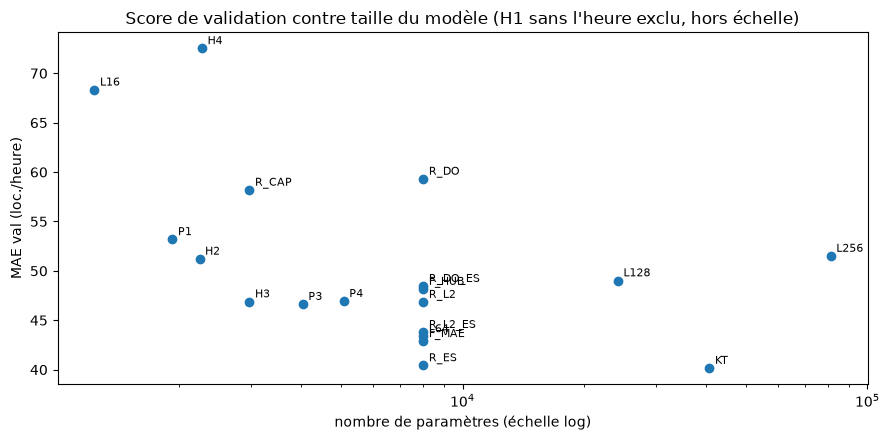

Choix final par la règle de parcimonie, sur tous les MLP horaires :


,entrées,architecture,paramètres,perte,régularisation,MAE train,MAE val,min MAE val,écart val/train,époque min val,bruit val
id,,,,,,,,,,,
KT,heure one-hot,128-128-128,40705,MAE,arrêt précoce (p=20),20.12,40.16,40.16,2.00,13,3.89
R_ES,heure one-hot,64-64,8001,MAE,arrêt précoce (p=20),18.77,40.42,40.42,2.15,31,0.53
F_MAE,heure one-hot,64-64,8001,MAE,aucune,14.63,42.88,40.42,2.93,31,0.73
L64,heure one-hot,64-64,8001,MSE,aucune,16.27,43.36,42.51,2.66,41,0.07
R_L2_ES,heure one-hot,64-64,8001,MAE,"L2 0.0001, arrêt précoce (p=20)",19.55,43.79,43.79,2.24,42,0.96
P3,heure one-hot,32-32-32,4033,MSE,aucune,18.66,46.63,45.14,2.50,21,0.14
R_L2,heure one-hot,64-64,8001,MAE,L2 0.0001,15.36,46.84,43.79,3.05,42,0.52
H3,heure one-hot,32-32,2977,MSE,aucune,18.11,46.89,44.39,2.59,40,0.17
P4,heure one-hot,32-32-32-32,5089,MSE,aucune,17.33,46.93,43.17,2.71,18,0.26


Meilleure MAE val : 40.16. Seuil à 2% : 40.96. Candidats sous le seuil : ['R_ES', 'KT'].
=> je retiens R_ES (64-64, 8001 paramètres).


In [48]:
# Parcimonie : MAE de validation en fonction du nombre de paramètres (jeu horaire seulement)
t = pd.DataFrame([RESULTATS[i] for i in IDS_H if RESULTATS[i]["entrées"] != "sans heure"])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(t["paramètres"], t["MAE val"])
for _, r in t.iterrows():
    ax.annotate(r["id"], (r["paramètres"], r["MAE val"]), textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.set(xscale="log", xlabel="nombre de paramètres (échelle log)", ylabel="MAE val (loc./heure)",
       title="Score de validation contre taille du modèle (H1 sans l'heure exclu, hors échelle)")
plt.tight_layout(); plt.show()
print("Choix final par la règle de parcimonie, sur tous les MLP horaires :")
ID_FINAL = choisir(IDS_H)

**Modèle retenu : R_ES.** KT (40,2 ; 40 705 paramètres) et R_ES (40,4 ; 8 001 paramètres) passent le seuil de 2 %. L'écart (0,6 %) est plus petit que l'agitation des courbes : la parcimonie garde **R_ES, deux couches de 64 neurones, heure en one-hot, perte MAE, arrêt précoce**.

## 10. Évaluation finale du modèle horaire retenu sur le jeu de test

### 10.1 Score de test

Première et seule utilisation du test pour le modèle horaire, sur octobre à décembre 2012.

In [49]:
cfg_f = CONFIGS[ID_FINAL]; d_f = cfg_f["data"]; m_f = MODELES[ID_FINAL]
pred_test_h = d_f.predire(m_f, "test")
MAE_TEST_H = mae(d_f.y["test"], pred_test_h)
refs_test = refs_horaires("test")
TEST_H = pd.DataFrame({"modèle": [f"MLP retenu {ID_FINAL}"] + list(refs_test),
                       "MAE test (loc./heure)": [MAE_TEST_H] + list(refs_test.values())}).round(1)
TEST_H["gain vs médiane"] = (1 - TEST_H["MAE test (loc./heure)"] / refs_test["médiane du train"]).map(lambda v: f"{v:.0%}" if abs(v) >= 0.005 else "0%")
print(f"MAE val du modèle retenu : {RESULTATS[ID_FINAL]['MAE val']:.1f} | cnt moyen test : {d_f.y['test'].mean():.1f}")
TEST_H

MAE val du modèle retenu : 40.4 | cnt moyen test : 219.2


,modèle,MAE test (loc./heure),gain vs médiane
0,MLP retenu R_ES,45.1,72%
1,médiane du train,161.1,0%
2,moyenne du train,156.6,3%
3,moyenne du train par heure,99.9,38%


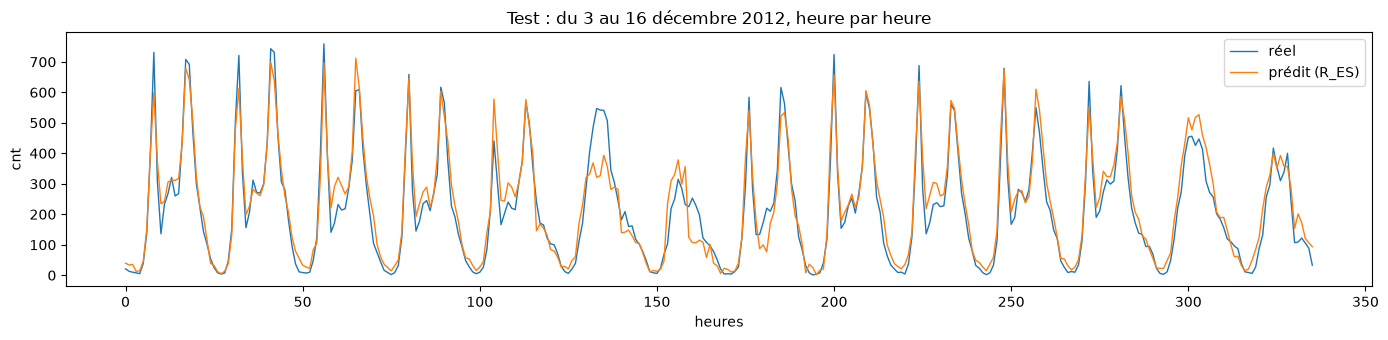

In [50]:
# Un aperçu : deux semaines de test, valeurs réelles contre prédictions
masque = (hour.loc[d_f.masques["test"], "dteday"] >= "2012-12-03").to_numpy() & \
         (hour.loc[d_f.masques["test"], "dteday"] <= "2012-12-16").to_numpy()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(d_f.y["test"][masque], label="réel", lw=1)
ax.plot(pred_test_h[masque], label=f"prédit ({ID_FINAL})", lw=1)
ax.set(title="Test : du 3 au 16 décembre 2012, heure par heure", xlabel="heures", ylabel="cnt"); ax.legend()
plt.tight_layout(); plt.show()

**Score de test : 45,1 vélos par heure**, contre 40,4 en validation : l'époque d'arrêt avait été choisie sur la validation, et le test est une autre saison. C'est **72 % d'erreur en moins** que la médiane constante (161,1) et 55 % de moins que la moyenne par heure (99,9). L'erreur vaut 20,6 % du niveau moyen du test. Sur deux semaines, le modèle suit bien les pics du matin et du soir.

### 10.2 Essai de contrôle : découpage aléatoire

Même configuration, avec un découpage aléatoire des heures (75 % / 12,5 % / 12,5 %), pour chiffrer l'argument 2 de la partie 4. J'ajoute la MAE relative (MAE divisée par le niveau moyen du test).

Tailles : {'train': 13074, 'val': 2144, 'test': 2161}


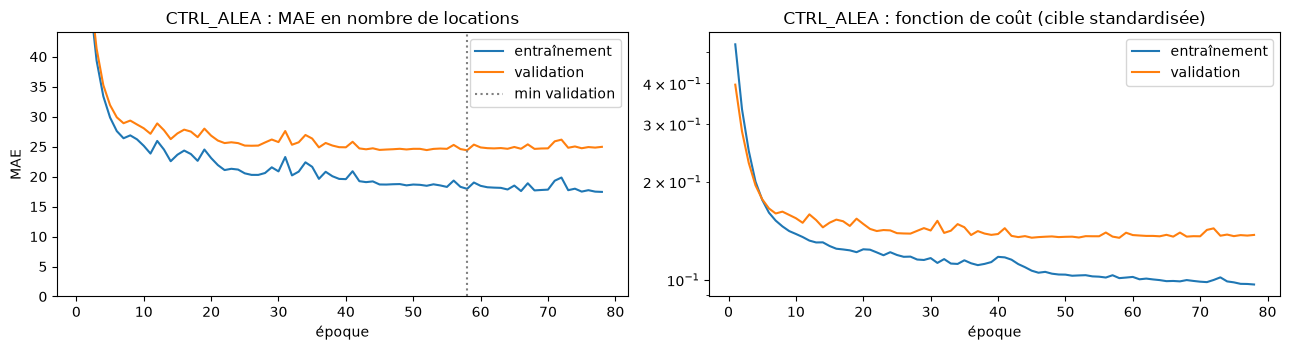

CTRL_ALEA | 64-64 | 8001 param. | perte MAE | rég. arrêt précoce (p=20)
   MAE train = 18.0 | MAE val = 24.4 (min 24.4 à l'époque 58/78, bruit des 10 dernières époques ±0.5) | écart val/train = 1.36 | 13 s


,découpage,MAE test (loc./heure),cnt moyen du test,MAE relative (MAE / cnt moyen)
0,chronologique,45.1,219.2,20.6%
1,aléatoire,24.1,182.5,13.2%


In [51]:
# Contrôle : même configuration, mais découpage aléatoire avec les mêmes proportions
rng = np.random.default_rng(SEED)
u = rng.random(len(hour))
jeux_alea = np.where(u < 0.75, "train", np.where(u < 0.875, "val", "test"))
D_alea = Donnees(hour, cfg_f["data"].mode_heure, jeux_alea, "horaire")
print("Tailles :", {j: int(m.sum()) for j, m in D_alea.masques.items()})
cfg_c = {k: v for k, v in cfg_f.items()}; cfg_c["data"] = D_alea
essai("CTRL_ALEA", jeu="horaire (découpage aléatoire)", **cfg_c)
MAE_TEST_ALEA = mae(D_alea.y["test"], D_alea.predire(MODELES["CTRL_ALEA"], "test"))
CTRL = pd.DataFrame({"découpage": ["chronologique", "aléatoire"],
                     "MAE test (loc./heure)": [MAE_TEST_H, MAE_TEST_ALEA],
                     "cnt moyen du test": [d_f.y["test"].mean(), D_alea.y["test"].mean()]})
CTRL["MAE relative (MAE / cnt moyen)"] = (CTRL["MAE test (loc./heure)"] / CTRL["cnt moyen du test"]).map("{:.1%}".format)
CTRL.round(1)

**Résultat du contrôle.** La MAE de test tombe à 24,1 contre 45,1 (en relatif, de 20,6 % à 13,2 %) : les heures voisines des heures testées étaient dans l'entraînement, la tâche est plus facile. Le score honnête pour prévoir le futur est **45,1**.

## 11. Acte 3 : comparaison journalier / horaire sur le total journalier

Les MAE des actes 1 et 2 ne se comparent pas (vélos par jour contre vélos par heure). Je ramène donc les deux modèles retenus à la même cible : **le total de locations par jour, sur les 92 mêmes jours de test**. Le modèle journalier (J3) le prédit directement ; pour le modèle horaire (R_ES), j'additionne ses prédictions de chaque jour.

Je somme sur les heures présentes dans `hour.csv`, ce qui avantage le modèle horaire les jours très incomplets (29 et 30 octobre) : je donne donc aussi le résultat sans ces jours.

In [52]:
# Modèle journalier : prédiction directe des jours de test
pred_j = DJ.predire(MODELES[ID_JOUR], "test")
jours_test = day.loc[DJ.masques["test"], "dteday"].to_numpy()
# Modèle horaire : somme des prédictions par jour (sur les heures présentes dans hour.csv)
somme_h = pd.Series(pred_test_h, index=hour.loc[d_f.masques["test"], "dteday"].to_numpy()).groupby(level=0).sum()
somme_h = somme_h.reindex(jours_test)
y_j = DJ.y["test"]
assert len(somme_h) == len(y_j) == 92 and not somme_h.isna().any()

A3 = pd.DataFrame({
    "modèle": [f"journalier {ID_JOUR}", f"horaire {ID_FINAL}, sommé par jour", "médiane journalière du train"],
    "MAE test (loc./jour)": [mae(y_j, pred_j), mae(y_j, somme_h.values), mae(y_j, np.full(len(y_j), med_j))]}).round(0)
A3["MAE relative"] = (A3["MAE test (loc./jour)"] / y_j.mean()).map("{:.1%}".format)
print("Jours de test :", len(y_j), "| cnt moyen :", round(y_j.mean()))
A3

Jours de test : 92 | cnt moyen : 5165


,modèle,MAE test (loc./jour),MAE relative
0,journalier J3,803.0,15.5%
1,"horaire R_ES, sommé par jour",670.0,13.0%
2,médiane journalière du train,1911.0,37.0%


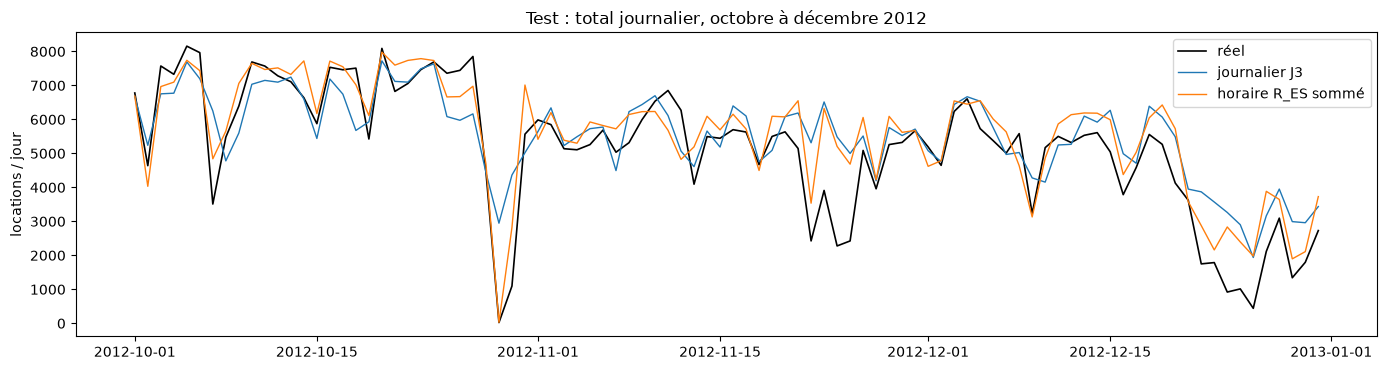

Les 5 jours les plus mal prédits par le modèle journalier :
      jour   réel  erreur journalier  erreur horaire sommé  heures présentes
2012-10-30 1096.0             3268.0                1726.0                11
2012-11-24 2277.0             3209.0                2929.0                24
2012-10-29   22.0             2924.0                   6.0                 1
2012-11-22 2425.0             2888.0                1110.0                24
2012-10-07 3510.0             2739.0                1331.0                24

Sensibilité, jours avec au moins 22 heures enregistrées (90 jours) : MAE journalier = 752, MAE horaire sommé = 665


In [53]:
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(jours_test, y_j, label="réel", color="black", lw=1.2)
ax.plot(jours_test, pred_j, label=f"journalier {ID_JOUR}", lw=1)
ax.plot(jours_test, somme_h.values, label=f"horaire {ID_FINAL} sommé", lw=1)
ax.set(title="Test : total journalier, octobre à décembre 2012", ylabel="locations / jour"); ax.legend()
plt.tight_layout(); plt.show()

err = pd.DataFrame({"jour": jours_test, "réel": y_j, "erreur journalier": np.abs(y_j - pred_j),
                    "erreur horaire sommé": np.abs(y_j - somme_h.values),
                    "heures présentes": n_heures.reindex(jours_test).to_numpy()})
print("Les 5 jours les plus mal prédits par le modèle journalier :")
print(err.sort_values("erreur journalier", ascending=False).head(5).round(0).to_string(index=False))
complets = err["heures présentes"] >= 22
print(f"\nSensibilité, jours avec au moins 22 heures enregistrées ({int(complets.sum())} jours) : "
      f"MAE journalier = {err.loc[complets, 'erreur journalier'].mean():.0f}, "
      f"MAE horaire sommé = {err.loc[complets, 'erreur horaire sommé'].mean():.0f}")

**Résultat : le modèle horaire sommé gagne.** Sur les 92 jours de test :

- modèle journalier J3 : **803** vélos par jour d'erreur (15,5 % du niveau moyen) ;
- modèle horaire R_ES, sommé par jour : **670** (13,0 %) ;
- médiane journalière constante : 1 911 (37,0 %).

Le modèle horaire fait environ 17 % d'erreur en moins, et reste devant sans les jours incomplets (665 contre 752). **Prudence** : il a eu 20 essais réglés pas à pas, le modèle journalier 3, donc une partie de l'écart vient de cet effort de réglage. Le reste s'explique plausiblement par 13 003 exemples au lieu de 547, et une météo vue heure par heure.

### TensorBoard

Chaque essai a écrit ses courbes dans `logs/`. Sur Colab, la cellule suivante ouvre TensorBoard ; en local, elle indique la commande à lancer.

In [54]:
if not AVEC_TB:
    print("TensorBoard n'est pas installé : pas de journaux à afficher.")
elif "google.colab" in sys.modules:
    get_ipython().run_line_magic("load_ext", "tensorboard")
    get_ipython().run_line_magic("tensorboard", "--logdir logs")
else:
    print("Hors Colab : lancer `tensorboard --logdir logs` dans un terminal. Dossiers :", sorted(os.listdir("logs")))

Hors Colab : lancer `tensorboard --logdir logs` dans un terminal. Dossiers : ['CTRL_ALEA', 'F_HUB', 'F_MAE', 'H1', 'H2', 'H3', 'H4', 'J1', 'J2', 'J3', 'KT', 'L128', 'L16', 'L256', 'L64', 'P1', 'P3', 'P4', 'R_CAP', 'R_DO', 'R_DO_ES', 'R_ES', 'R_L2', 'R_L2_ES']


### Tableau récapitulatif final

Même tableau qu'en partie 9, avec en plus l'essai de contrôle en découpage aléatoire (sa MAE de validation porte sur un autre découpage : elle ne se compare pas aux autres lignes).

In [55]:
recapitulatif()

,jeu,entrées,architecture,paramètres,perte,régularisation,lr,MAE train,MAE val,min MAE val,unité MAE,écart val/train,époque min val,diagnostic
id,,,,,,,,,,,,,,
J1,journalier,journalier,16,561,MSE,aucune,0.001,230.69,1033.23,841.27,loc./jour,4.48,83,sur-apprentissage (val remonte après l'époque 83)
J2,journalier,journalier,256-256-256,140545,MSE,aucune,0.001,112.96,1290.02,539.30,loc./jour,11.42,10,sur-apprentissage fort + instabilité
J3,journalier,journalier,256-256-256,140545,MSE,arrêt précoce (p=30),0.001,466.23,539.30,539.30,loc./jour,1.16,10,"compromis par arrêt précoce, fragile (creux d'..."
H1,horaire,sans heure,32-32,2209,MSE,aucune,0.001,78.54,157.30,148.10,loc./heure,2.00,17,sous-apprentissage (il manque l'heure)
H2,horaire,heure brute,32-32,2241,MSE,aucune,0.001,21.02,51.22,51.14,loc./heure,2.44,98,"bon compromis, pas tout à fait convergé"
H3,horaire,heure one-hot,32-32,2977,MSE,aucune,0.001,18.11,46.89,44.39,loc./heure,2.59,40,"bon compromis, léger sur-apprentissage en fin"
H4,horaire,heure sin/cos,32-32,2273,MSE,aucune,0.001,19.98,72.53,55.52,loc./heure,3.63,24,sur-apprentissage net
P1,horaire,heure one-hot,32,1921,MSE,aucune,0.001,21.26,53.19,50.71,loc./heure,2.50,54,léger sous-apprentissage
P3,horaire,heure one-hot,32-32-32,4033,MSE,aucune,0.001,18.66,46.63,45.14,loc./heure,2.50,21,"bon compromis, léger sur-apprentissage"


## 12. Conclusion argumentée

### Le modèle retenu

**R_ES** : deux couches cachées de 64 neurones (ReLU), **8 001 paramètres**, heure en one-hot, perte MAE, Adam (0,001), lots de 128, arrêt précoce (poids de l'époque 31).

| | MAE (vélos par heure) |
| --- | --- |
| Validation (juillet-septembre 2012) | 40,4 |
| **Test (octobre-décembre 2012)** | **45,1** |
| Référence médiane constante, sur le test | 161,1 |
| Référence moyenne par heure, sur le test | 99,9 |

### Réponses aux six questions d'analyse

1. **Architectures** : 20 MLP sur le jeu horaire (1 à 4 couches, 16 à 256 neurones, de 1 233 à 81 153 paramètres) et 3 sur le jeu journalier. Au-delà de deux couches, la profondeur n'apporte presque rien ; la largeur a un optimum à 64 neurones.
2. **Fonctions de coût** : MAE 42,9, MSE 43,4, Huber 48,2. La MAE gagne de peu, dans le bruit, mais atteint un meilleur minimum (40,4).
3. **Situations d'apprentissage** (détail dans le tableau) : sous-apprentissage pour H1, P1 et le dropout ; bon compromis pour H2, H3, P3, L64, F_MAE, R_ES, R_L2_ES et KT ; sur-apprentissage pour les autres, dont les trois modèles journaliers. Comme la validation est plus chargée que le train, je me suis surtout fié à la forme des courbes.
4. **Corrections** : seul l'arrêt précoce améliore le score (42,9 → 40,4 en horaire, 1 290 → 539 en journalier). Le dropout, la L2 et la réduction de capacité le dégradent, même au même critère.
5. **Recherche d'hyper-paramètres** : HyperBand, 90 essais ; sa meilleure configuration (3 × 128) fait 40,2 contre 40,4, sans gain net.
6. **Parcimonie** : R_ES est cinq fois plus petit que KT pour 0,6 % d'écart, et plus stable : **c'est lui que je retiens.**

### Réponse à la question du projet

Au niveau horaire, **donner l'heure divise l'erreur par 3** (157 → 47 vélos par heure), et l'encodage compte (one-hot 46,9, sinus/cosinus 72,5). Sur le total journalier, le modèle horaire sommé bat le modèle journalier : 670 contre 803 vélos par jour (−17 %), en partie grâce à un réglage plus poussé.

### Limites

- **Une seule graine** : des écarts de 1 ou 2 vélos par heure ne sont pas significatifs.
- **Validation sur un seul été** : mes choix sont peut-être adaptés à cette saison.
- **Croissance du service** portée par `yr` seul : pas de prévision possible pour 2013.
- **Non testé** : transformation logarithmique de la cible, autres valeurs de `delta`, de L2 et du taux d'apprentissage.